# Oddball information across areas — LFP spectral MI

**OpenScope Community Predictive Processing** · DANDI `001637`

> **Before you run it.** Replicating the analysis from scratch streams roughly 60 sessions
> from DANDI and takes **several hours**; stages 1–2 dominate. It writes **about 400 MB** of
> intermediate data (per-animal trial PSDs) plus the figure panels. Everything is resumable:
> re-running skips whatever is already saved. If you only want the figures, the panels and
> `viewer.html` produced at the end are enough; no recomputation is needed to browse them.

How much information does the LFP power spectrum carry about each prediction error, and
in which areas and frequencies? The notebook runs the same analysis in every session
context listed in `RUN_CONTEXTS` (all four by default), in one pass:

| Context | Block | Oddballs |
|---|---|---|
| `standard` | Standard mismatch block (passive) | `orientation_45`, `orientation_90`, `halt`, `omission` |
| `sensorimotor` | Sensory-motor mismatch block (closed loop: running drives the grating) | `motor_orientation_45`, `motor_orientation_90`, `motor_halt`, `motor_omission` |
| `sequence` | Sequence mismatch block (90°, 45°, 0°, 45°, blank, repeating) | `orientation_45`, `orientation_90`, `halt`, `omission` in the 3rd slot |
| `duration` | Duration mismatch block (timing deviants) | early/late gratings, classified from the trial timing (`isi_150ms`, `isi_500ms`, `isi_1000ms`), plus `omission` |

**Run all cells once, top to bottom.** Every stage loops over the contexts, and each
context writes to its own results folder. Anything already saved is skipped, so a
re-run only computes what is missing. Section 6 renders every panel of the main figure
(heatmap, spectra, example traces) as PNGs, and section 7 is the interactive main figure:
pick paradigm, area and oddball. Section 8 writes the same figure as `viewer.html`.

For every animal the notebook:

1. streams the session and reads the trial table of the context's block;
2. randomly samples up to **10 LFP channels per main area**;
3. cuts a **1 s chunk centred on each trial** (35 trials per oddball type, up to 400
   standards; for timing deviants, centred on the moment the violation happens, see
   below) and computes its PSD with a **Gaussian taper whose FWHM equals the stimulus
   duration**, averaged into 50 log-spaced bins from 4 to 100 Hz;
4. computes the **mutual information** between log-power and trial identity (standard vs.
   each oddball), per area and per frequency.

The main figure combines, for a chosen paradigm, area and oddball: an example LFP trace
with its spectrogram, the area's power spectrum per condition, and the paradigm's MI
heatmaps (one per oddball type: areas on x, frequency on y, colour intensity = MI, hue =
oddball type, the same colours as in the spectra and traces).

**Main areas** follow Table 1 of the project manuscript (Neuropixels cohorts: V1, LM, M1,
M2, PL/IL/ACA, RL, LGN) plus the striatum (CP) and the hippocampal and thalamic structures
the probes pass through (CA1, CA2, CA3, DG, SUB, LP). Edit `MAIN_AREAS` to change this.

**Persistence.** Results are written as they are produced: to Google Drive when running on
Colab (optional, on by default), otherwise to a local folder. One file of trial PSDs per
animal, then one file of MI per animal. Both stages skip animals already saved, so the
notebook can be interrupted and resumed, and the MI can be recomputed with new parameters
without streaming the data again. The last cell writes `viewer.html`, a standalone web page
version of the interactive figure.

**Design choices worth knowing about**
- *MI estimator*: Gaussian-copula MI (Ince et al., 2017, *Hum Brain Mapp*). Rank-based, so
  independent of LFP units or scaling, and closed-form, so hundreds of shuffles are cheap.
- *Bias*: each value is corrected by subtracting the mean MI of label-shuffled data; the
  shuffles also give a per-animal p-value.
- *Balance*: every estimate uses equal numbers of standards and oddballs (standards redrawn
  `N_DRAWS` times and averaged). With balanced classes the ceiling is 1 bit.
- *Standards, standard context*: the first `SKIP_AFTER_DEVIANT` standards after any oddball
  are excluded, so the standard class is not contaminated by post-oddball recovery.
- *Standards, sensorimotor context*: the closed-loop "standard" rows are 33 ms display
  frames of continuous, wheel-coupled flow, not discrete presentations. Standards are
  therefore **pseudo-trials** at random times in the block, well away from any oddball.
  Running changes the LFP on its own (hippocampal theta above all), so the pseudo-trials are
  **matched to the oddballs on running speed**, and in every MI draw each oddball type gets
  its own speed-matched set of standards.
- *Standards, sequence context*: only standards in the **3rd slot** of the sequence (the
  slot where oddballs occur, normally 0°) are used, and the whole sequence after an oddball
  is skipped. Note that a 45° or 90° grating in that slot is not a new stimulus — both
  orientations appear elsewhere in every sequence — so here orientation oddballs are
  violations of *order*, not of feature novelty.
- *What the duration block is*: every grating is the same (0°, 343 ms). What varies is
  the gray gap before a grating: 343 ms for standards, and 150 ms (the grating comes
  early), 500 ms or 1000 ms (it comes late) for the deviants, which the table labels only
  as `jitter`; the notebook names them from their measured gap. Omissions are the fourth
  oddball. Halt only occurs in the control blocks.
- *Alignment, duration context*: each chunk is centred on the moment the violation becomes
  detectable, i.e. whichever comes first of the actual event and the expected one. A grating
  that is **too short** is centred on its (early) offset; one that is **too long** on the
  expected offset, when it fails to turn off. A gray interval that is **too short** is
  centred on the early onset of the grating; one that is **too long** on the expected
  onset, when nothing appears yet (with a 500 ms gap the late grating still falls inside
  the taper; with 1000 ms it does not). Standards are centred on the same event (their offset or the
  next onset), so each contrast compares like with like. Omissions stay stimulus-centred. Without this, any difference in running
  between the two classes would show up as MI that has nothing to do with the mismatch.

## 0 · Setup

In [3]:
#@title Install dependencies
!pip install -q dandi pynwb remfile

In [4]:
#@title Storage — Google Drive if running on Colab (optional), otherwise a local folder
import os

try:
    import google.colab                        # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

USE_DRIVE    = True                           #@param {type:"boolean"}
DRIVE_SUBDIR = "OpenScope_PP/oddball_MI"      #@param {type:"string"}
LOCAL_DIR    = "./oddball_MI"                 #@param {type:"string"}

# On Colab with USE_DRIVE, results persist on Google Drive (a Colab runtime's own disk is
# wiped when it disconnects). Anywhere else -- or with USE_DRIVE off -- they go to LOCAL_DIR.
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = os.path.join("/content/drive/MyDrive", DRIVE_SUBDIR)
else:
    RESULTS_DIR = os.path.abspath(LOCAL_DIR)
    if IN_COLAB:
        print("Drive is off: results live on this Colab runtime and are lost when it disconnects.")
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"Results: {RESULTS_DIR}")

Mounted at /content/drive
Results: /content/drive/MyDrive/OpenScope_PP/oddball_MI


In [5]:
#@title Imports and configuration
import re
import glob
import json
import logging
import warnings
warnings.filterwarnings("ignore")
logging.getLogger("dandi").setLevel(logging.CRITICAL)   # silences harmless 403 HEAD noise

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import periodogram
from scipy.special import ndtri
from scipy.stats import rankdata, wilcoxon
from scipy.interpolate import interp1d

# ── Context ------------------------------------------------------------------
# Every stage below runs over all of these; remove any you do not want.
RUN_CONTEXTS = ["standard", "sensorimotor", "sequence", "duration"]

CONTEXTS = {
    "standard": {
        "label": "Standard mismatch",
        "table_regex": r"^Standard mismatch block_presentations$",
        "standard": "standard",
        "oddballs": ["orientation_45", "orientation_90", "halt", "omission"],
        "standards_from": "presentations",     # discrete standard presentations
        "match_running": False,
    },
    "sensorimotor": {
        "label": "Sensorimotor mismatch (closed loop)",
        "table_regex": r"(?i)^(sensory.?motor|motor).*(mismatch|oddball).*_presentations$",
        "standard": "standard",
        "oddballs": ["motor_orientation_45", "motor_orientation_90", "motor_halt",
                     "motor_omission"],
        "standards_from": "pseudo",            # standard rows are 33 ms closed-loop frames
        "match_running": True,
    },
    "sequence": {
        "label": "Sequence mismatch",
        "table_regex": r"(?i)^sequen\w*.*(mismatch|oddball).*_presentations$",
        "standard": "standard",
        "oddballs": ["orientation_45", "orientation_90", "halt", "omission"],
        "standards_from": "presentations",
        "standard_position": 3,                # only standards in the oddball slot (normally 0°)
        "skip_after": 5,                       # one whole sequence after any oddball
        "match_running": False,
    },
    "duration": {
        "label": "Duration mismatch",
        "table_regex": r"(?i)^(duration|jitter|temporal|timing)\w*.*(mismatch|oddball).*_presentations$",
        "standard": "standard",
        "oddballs": None,                      # classified from trial timing (TIMING_TOL)
        "psd_version": 2,                      # v2: gray interval before the grating is checked
        "standards_from": "presentations",
        "match_running": False,
    },
}
TRIALTYPE_COLS = ("TrialType", "Trial_Type", "trial_type")

BASE_LABELS = {"orientation_45": "Orientation 45°", "orientation_90": "Orientation 90°",
               "halt": "Halt", "omission": "Omission"}


def base_of(oddball):
    return re.sub(r"^motor_", "", oddball)


def label_of(oddball):
    b = base_of(oddball)
    if b in BASE_LABELS:
        return BASE_LABELS[b]
    m = re.match(r"(duration|isi)_(\d+)ms$", b)
    if m:
        ms = int(m.group(2))
        if m.group(1) == "duration":
            return f"Grating {ms} ms ({'short' if ms < 343 else 'long'})"
        return f"Gap {ms} ms ({'early' if ms < 343 else 'late'})"
    return b


def order_oddballs(names):
    # Timing deviants by kind and length, then the feature oddballs in their usual order.
    def key(n):
        b = base_of(n)
        m = re.match(r"(duration|isi)_(\d+)ms$", b)
        if m:
            return (0 if m.group(1) == "duration" else 1, int(m.group(2)))
        if b in BASE_LABELS:
            return (2, list(BASE_LABELS).index(b))
        return (3, 0)
    return sorted({str(n) for n in names}, key=key)


# ── Dataset ------------------------------------------------------------------
DANDISET_ID      = "001637"
DANDISET_VERSION = "draft"      # switch to a published version once one exists

# ── Main areas: display name -> regex on the electrode `location` (Allen CCF acronym)
# Anchored patterns keep sibling areas apart: VISp does not swallow VISpm/VISpl/VISpor,
# VISl does not swallow VISli. Order here is the order on the figure's x axis.
MAIN_AREAS = {
    "LGN":  r"^LGd",
    "V1":   r"^VISp(\d|$)",
    "LM":   r"^VISl(\d|$)",
    "RL":   r"^VISrl",
    "AL":   r"^VISal",
    "PM":   r"^VISpm",
    "AM":   r"^VISam",
    "M1":   r"^MOp(\d|$)",
    "M2":   r"^MOs(\d|$)",
    "ACA":  r"^ACA",
    "PL":   r"^PL(\d|$)",
    "ILA":  r"^ILA",
    "CP":   r"^(CP|STR)$",   # dorsal striatum (caudoputamen); bare STR if unassigned
    "LP":   r"^LP$",
    "CA1":  r"^CA1$",
    "CA2":  r"^CA2$",
    "CA3":  r"^CA3$",
    "DG":   r"^DG",
    "SUB":  r"^(SUB|ProS)",
}
AREA_ORDER = list(MAIN_AREAS)

# ── Channel sampling ---------------------------------------------------------
MAX_CH_PER_AREA = 10       # random channels per main area (all of them if fewer)
RNG_SEED        = 42       # combined with the subject id, so each animal is reproducible

# ── Trials -------------------------------------------------------------------
MAX_STANDARDS      = 400   # standards (or pseudo-standards) kept per animal
N_PER_ODDBALL      = 35    # random trials kept per oddball type
SKIP_AFTER_DEVIANT = 2     # standards right after an oddball are excluded (sequence: 5)

# Duration context: how a deviant's timing is classified
TIMING_TOL  = 0.025        # s; a duration or gray interval this far from the standard's is a deviant
TIMING_STEP = 0.05         # s; deviant lengths are rounded to this for naming (absorbs frame jitter)

# Sensorimotor context: pseudo-standards and running speed
PSEUDO_CANDIDATES = 4000   # random candidate times drawn before exclusion and matching
EXCLUDE_BEFORE    = 0.5    # s; no pseudo-standard chunk may come this close before an oddball
EXCLUDE_AFTER     = 2.0    # s; ...or this close after one ends
RUNNING_SERIES    = None   # e.g. "running/running_speed"; None -> auto-detect (see section 2)
MIN_SPEED         = None   # cm/s; e.g. 2.0 keeps only running trials, in both classes

# ── Chunks and PSD -----------------------------------------------------------
CHUNK_DUR   = 1.0          # s, centred on the middle of the stimulus
TAPER_FWHM  = None         # s; None -> median standard duration of each session (~0.35 s)
# The Gaussian taper is what sets the effective window: at the edges of the stimulus it
# weighs 0.5, and at the neighbouring presentations (~0.7 s away) it is below 0.5 %, so
# they do not leak in even though the 1 s chunk reaches them.
FMIN, FMAX   = 4.0, 100.0
N_FREQ_BINS  = 50          # log-spaced bins; power is averaged within each bin
NFFT         = 16384       # zero-padded FFT so even the narrowest low bin holds several points
FREQ_EDGES   = np.geomspace(FMIN, FMAX, N_FREQ_BINS + 1)
FREQ_CENTERS = np.sqrt(FREQ_EDGES[:-1] * FREQ_EDGES[1:])   # geometric centres
# Note: a Gaussian taper with FWHM ~0.35 s resolves ~1.8 Hz (FWHM of its power kernel).
# Log bins are narrower than that below ~25 Hz, so there neighbouring bins oversample
# the same spectral information rather than being independent estimates.

# ── Reading ------------------------------------------------------------------
MAX_READ_SPAN_S = 60.0     # trials are read in batches no longer than this
MAX_READ_GAP_S  = 3.0      # ...and a gap longer than this starts a new batch

# ── Mutual information -------------------------------------------------------
N_DRAWS    = 20            # balanced redraws of the larger class
N_SHUFFLE  = 200           # label shuffles per draw (bias correction + p-values)
MIN_TRIALS = 20            # per class; fewer and the area/oddball is skipped

# ── Group statistics ---------------------------------------------------------
MIN_ANIMALS_SHOW  = 3      # areas recorded in fewer animals are not plotted
MIN_ANIMALS_STATS = 6      # one-sided Wilcoxon needs >= 6 animals to reach p < 0.05
ALPHA             = 0.05   # FDR (Benjamini-Hochberg) across area x frequency, per oddball

MI_TAG = f"gcmi_d{N_DRAWS}_s{N_SHUFFLE}_c{int(CHUNK_DUR*1000)}ms_gauss_b{N_FREQ_BINS}log"


# ── Folders: the standard context keeps the original layout, so earlier results load as-is
def context_dirs(ctx):
    base = RESULTS_DIR if ctx == "standard" else os.path.join(RESULTS_DIR, ctx)
    return {k: os.path.join(base, k) for k in ("psd", "mi", "figures")}


for _c in RUN_CONTEXTS:
    for d in context_dirs(_c).values():
        os.makedirs(d, exist_ok=True)
print("Contexts to run:", RUN_CONTEXTS)

Contexts to run: ['standard', 'sensorimotor', 'sequence', 'duration']


In [6]:
#@title Sessions
# Standard context: the same 15 sessions as the VISp2/3 showcase notebook, hard-coded so
# the figure does not change as DANDI 001637 grows.
STANDARD_SESSION_PATHS = [
    "sub-834687/sub-834687_ses-ecephys-834687-2026-03-18-15-50-10_ecephys.nwb",
    "sub-830851/sub-830851_ses-ecephys-830851-2026-03-17-10-46-04_ecephys.nwb",
    "sub-830848/sub-830848_ses-ecephys-830848-2026-03-04-15-34-54_ecephys.nwb",
    "sub-834691/sub-834691_ses-ecephys-834691-2026-02-17-10-49-35_ecephys.nwb",
    "sub-830795/sub-830795_ses-ecephys-830795-2026-02-24-15-08-59_ecephys.nwb",
    "sub-830794/sub-830794_ses-ecephys-830794-2026-01-27-11-25-31_ecephys.nwb",
    "sub-830846/sub-830846_ses-ecephys-830846-2026-03-11-10-19-32_ecephys.nwb",
    "sub-830847/sub-830847_ses-ecephys-830847-2026-03-11-15-46-40_ecephys.nwb",
    "sub-830849/sub-830849_ses-ecephys-830849-2026-03-06-10-51-58_ecephys.nwb",
    "sub-830852/sub-830852_ses-ecephys-830852-2026-02-24-10-20-58_ecephys.nwb",
    "sub-832691/sub-832691_ses-ecephys-832691-2026-03-25-10-22-33_ecephys.nwb",
    "sub-834686/sub-834686_ses-ecephys-834686-2026-03-25-15-47-48_ecephys.nwb",
    "sub-848387/sub-848387_ses-ecephys-848387-2026-05-05-15-55-50_ecephys.nwb",
    "sub-848390/sub-848390_ses-ecephys-848390-2026-05-05-10-08-25_ecephys.nwb",
    "sub-820454/sub-820454_ses-ecephys-820454-2025-11-05-15-21-15_ecephys.nwb",
]

# Other contexts: section 2 scans the animals' other NWB files once and stores the list of
# tables in each one (an inventory in the results folder). Each context's sessions are then derived from
# that inventory with the context's block-name pattern, so a pattern can be fixed without
# re-scanning, and a context that matched nothing is reported instead of silently skipped.
INVENTORY_FILE = os.path.join(RESULTS_DIR, "nwb_tables_inventory.json")


def subject_of(path):
    return path.split("/")[0].replace("sub-", "")


def load_inventory():
    if not os.path.exists(INVENTORY_FILE):
        return None
    with open(INVENTORY_FILE) as f:
        return json.load(f)


def load_sessions(ctx):
    # Session paths for a context (one per animal that has the block); None before the scan.
    if ctx == "standard":
        return list(STANDARD_SESSION_PATHS)
    inv = load_inventory()
    if inv is None:
        return None
    regex = CONTEXTS[ctx]["table_regex"]
    out = []
    for p in STANDARD_SESSION_PATHS:
        subj = subject_of(p)
        hits = [f for f in sorted(inv) if f.startswith(f"sub-{subj}/")
                and any(re.search(regex, t) for t in inv[f])]
        if hits:
            out.append(hits[0])
    return out


def set_context(ctx):
    # Point every stage at one context: its settings, its folders and its sessions.
    global CONTEXT, CTX, STANDARD, ODDBALLS, PSD_DIR, MI_DIR, FIG_DIR, SESSION_PATHS
    CONTEXT, CTX = ctx, CONTEXTS[ctx]
    STANDARD, ODDBALLS = CTX["standard"], CTX["oddballs"]
    d = context_dirs(ctx)
    PSD_DIR, MI_DIR, FIG_DIR = d["psd"], d["mi"], d["figures"]
    SESSION_PATHS = load_sessions(ctx)
    return SESSION_PATHS


def banner(ctx):
    print(f"\n{'=' * 78}\n{CONTEXTS[ctx]['label']}\n{'=' * 78}")


for _c in RUN_CONTEXTS:
    _s = load_sessions(_c)
    print(f"{_c:>13}: " + (f"{len(_s)} sessions" if _s is not None
                           else "not scanned yet (section 2 finds them)"))

     standard: 15 sessions
 sensorimotor: 15 sessions
     sequence: 14 sessions
     duration: 14 sessions


## 1 · Helpers

In [7]:
#@title Streaming, electrodes and areas
def stream_nwb(filepath):
    # Open an NWB file straight from the DANDI S3 bucket; nothing is downloaded to disk.
    import h5py, remfile
    from dandi.dandiapi import DandiAPIClient
    from pynwb import NWBHDF5IO
    with DandiAPIClient() as client:
        asset = client.get_dandiset(DANDISET_ID, DANDISET_VERSION).get_asset_by_path(filepath)
        url = asset.get_content_url(follow_redirects=True, strip_query=True)
    io = NWBHDF5IO(file=h5py.File(remfile.File(url), "r"), mode="r")
    return io, io.read()


def list_nwb_assets():
    # Every NWB path in the dandiset.
    from dandi.dandiapi import DandiAPIClient
    with DandiAPIClient() as client:
        ds = client.get_dandiset(DANDISET_ID, DANDISET_VERSION)
        return sorted(a.path for a in ds.get_assets() if a.path.endswith(".nwb"))


def find_table(nwb, regex=None):
    # Name of the intervals table for this context (None if the session does not have it).
    regex = regex or CTX["table_regex"]
    for name in nwb.intervals.keys():
        if re.search(regex, name):
            return name
    return None


def lfp_series(nwb):
    return nwb.processing["ecephys"]["LFP"].electrical_series


def area_of(location):
    # Main area for a CCF acronym, or None if it is not one of MAIN_AREAS.
    for area, pattern in MAIN_AREAS.items():
        if re.match(pattern, location):
            return area
    return None


def lfp_channels(nwb):
    # One row per electrode that carries LFP: id, location, main area, series and column.
    # LFP is spatially subsampled, so the electrodes table alone is not a channel list.
    edf = nwb.electrodes.to_dataframe().reset_index()
    edf = edf.rename(columns={edf.columns[0]: "electrode_id"})
    loc = dict(zip(edf["electrode_id"].astype(int), edf["location"].astype(str)))

    rows = []
    for name, es in lfp_series(nwb).items():
        for col, eid in enumerate(es.electrodes.data[:]):
            eid = int(eid)
            rows.append({"electrode_id": eid, "location": loc.get(eid, ""),
                         "series": name, "col": col})
    df = pd.DataFrame(rows)
    df["area"] = df["location"].map(area_of)
    return df


def sample_channels(chans, max_per_area, rng):
    # Up to max_per_area random LFP channels from each main area present.
    pool = chans.dropna(subset=["area"])
    picked = []
    for a in AREA_ORDER:
        sub = pool[pool["area"] == a]
        if len(sub):
            picked.append(sub.sample(n=min(max_per_area, len(sub)),
                                     random_state=int(rng.integers(2**31))))
    return pd.concat(picked).reset_index(drop=True) if picked else pool.iloc[:0]

In [8]:
#@title Running speed
def timeseries_in(nwb):
    # Every object with data in processing modules and acquisition, keyed "module/name".
    out = {}
    for mod_name, mod in nwb.processing.items():
        for name, obj in getattr(mod, "data_interfaces", mod).items():
            if hasattr(obj, "data"):
                out[f"{mod_name}/{name}"] = obj
    for name, obj in getattr(nwb, "acquisition", {}).items():
        if hasattr(obj, "data"):
            out[f"acquisition/{name}"] = obj
    return out


def running_speed(nwb):
    # (timestamps, speed) of the running-speed series, or None if there is none.
    series = timeseries_in(nwb)
    if RUNNING_SERIES:
        name = RUNNING_SERIES
    else:
        cands = [k for k in series if re.search(r"(?i)speed", k.split("/")[-1])]
        cands.sort(key=lambda k: (not re.search(r"(?i)running", k), len(k)))
        if not cands:
            return None
        name = cands[0]
    ts_obj = series[name]
    v = np.asarray(ts_obj.data[:], dtype=float).ravel()
    if getattr(ts_obj, "timestamps", None) is not None:
        t = np.asarray(ts_obj.timestamps[:], dtype=float)
    else:
        t = ts_obj.starting_time + np.arange(len(v)) / float(ts_obj.rate)
    return t, v


def window_speed(speed, t0, t1):
    # Mean speed in each window [t0, t1); NaN if no speed data (or no samples) there.
    t0, t1 = np.atleast_1d(t0), np.atleast_1d(t1)
    if speed is None:
        return np.full(len(t0), np.nan)
    t, v = speed
    cs = np.r_[0.0, np.cumsum(np.nan_to_num(v))]
    i0, i1 = np.searchsorted(t, t0), np.searchsorted(t, t1)
    n = i1 - i0
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(n > 0, (cs[i1] - cs[i0]) / np.maximum(n, 1), np.nan)


def match_by_speed(cand_speed, odd_speed, n_total, rng):
    # Indices of candidates matched to the oddballs on speed (nearest neighbours, no reuse).
    # Every oddball claims the same number of candidates, so the matched standards inherit
    # the oddballs' speed distribution.
    k = int(np.ceil(n_total / max(1, np.isfinite(odd_speed).sum())))
    free = np.isfinite(cand_speed)
    chosen = []
    for s in rng.permutation(odd_speed[np.isfinite(odd_speed)]):
        d = np.where(free, np.abs(cand_speed - s), np.inf)
        pick = np.argsort(d)[:k]
        pick = pick[np.isfinite(d[pick])]
        free[pick] = False
        chosen.extend(pick.tolist())
    return np.array(chosen[:n_total], dtype=int)

In [9]:
#@title Trial table
def trial_type_col(df):
    for c in TRIALTYPE_COLS:
        if c in df.columns:
            return c
    raise KeyError(f"no trial-type column among {TRIALTYPE_COLS}: {list(df.columns)}")


def standard_mask(df, types):
    # Standard presentations eligible as standards (sequence context: 3rd slot only).
    is_std = types == STANDARD
    pos = CTX.get("standard_position")
    if pos is None:
        return is_std
    pos_col = next((c for c in df.columns
                    if re.search(r"(?i)trial.?in.?sequence|sequence.?position", c)), None)
    if pos_col is not None:
        return is_std & (pd.to_numeric(df[pos_col], errors="coerce").to_numpy() == pos)
    ori_col = next((c for c in df.columns if c.lower() == "orientation"), None)
    if ori_col is None:
        raise KeyError(f"no sequence-position or orientation column: {list(df.columns)}")
    # In the 90-45-0-45 sequence, 0° only occurs in the 3rd slot (0 rad == 0°).
    print("  ! no sequence-position column — using the 0° standards, which only occur in slot 3")
    ori = pd.to_numeric(df[ori_col], errors="coerce").to_numpy()
    return is_std & (np.abs(ori) < 1e-3)


def oddball_classes(df, types):
    # Oddball class (None for non-oddballs) and anchor for every row, plus the standard's
    # duration D0 and gray interval G0. Anchors: "centre" (stimulus middle), "offset",
    # "onset" (this grating's onset), "next_onset" (onset of the following grating).
    t0, t1 = df["start_time"].to_numpy(), df["stop_time"].to_numpy()
    nxt = np.r_[t0[1:], np.nan]
    dur, gap = t1 - t0, nxt - t1
    gap_before = t0 - np.r_[np.nan, t1[:-1]]
    is_std = types == STANDARD
    D0 = float(np.nanmedian(dur[is_std]))
    G0 = float(np.nanmedian(gap[is_std & np.r_[is_std[1:], False]]))
    cls = np.full(len(df), None, dtype=object)
    anchor = np.full(len(df), "centre", dtype=object)

    if CTX["oddballs"] is not None:
        hit = np.isin(types, CTX["oddballs"])
        cls[hit] = types[hit]
        return cls, anchor, D0, G0

    name = lambda x: int(round(x / TIMING_STEP) * TIMING_STEP * 1000)
    for i in np.flatnonzero(~is_std):
        raw = types[i]
        if base_of(raw) in BASE_LABELS:                 # e.g. omission: keep, stimulus-centred
            cls[i] = raw
        elif abs(dur[i] - D0) > TIMING_TOL:
            cls[i], anchor[i] = f"duration_{name(dur[i])}ms", "offset"
        elif np.isfinite(gap_before[i]) and abs(gap_before[i] - G0) > TIMING_TOL:
            # The gray interval before this grating was off: it came early or late.
            cls[i], anchor[i] = f"isi_{name(gap_before[i])}ms", "onset"
        elif np.isfinite(gap[i]) and abs(gap[i] - G0) > TIMING_TOL:
            cls[i], anchor[i] = f"isi_{name(gap[i])}ms", "next_onset"
        elif not raw.startswith("sequence_"):
            cls[i] = f"{raw}_unclassified"
    return cls, anchor, D0, G0


def anchor_times(df, idx, kind, D0, G0, is_oddball):
    # Time each chunk is centred on. Oddballs: the earlier of the actual and the expected
    # event (when the violation becomes detectable). Standards: the actual event.
    t0, t1 = df["start_time"].to_numpy()[idx], df["stop_time"].to_numpy()[idx]
    nxt = np.r_[df["start_time"].to_numpy()[1:], np.nan][idx]
    prev_stop = np.r_[np.nan, df["stop_time"].to_numpy()[:-1]][idx]
    if kind == "centre":
        return 0.5 * (t0 + t1)
    if kind == "offset":
        return t0 + np.minimum(t1 - t0, D0) if is_oddball else t1
    if kind == "onset":
        return prev_stop + np.minimum(t0 - prev_stop, G0) if is_oddball else t0
    if kind == "next_onset":
        return t1 + np.minimum(nxt - t1, G0) if is_oddball else nxt
    raise ValueError(kind)


def build_trials(nwb, rng, speed=None):
    # Standards (or speed-matched pseudo-standards) and oddballs, in time order.
    # Columns: start_time, stop_time, anchor_time (chunk centre), anchor, condition, speed.
    table = find_table(nwb)
    if table is None:
        raise KeyError(f"no table matching {CTX['table_regex']!r}: {list(nwb.intervals.keys())}")
    df = (nwb.intervals[table].to_dataframe()
          .sort_values("start_time").reset_index(drop=True))
    types = df[trial_type_col(df)].astype(str).to_numpy()
    t0_all, t1_all = df["start_time"].to_numpy(), df["stop_time"].to_numpy()
    spd_all = lambda idx: window_speed(speed, t0_all[idx], t1_all[idx])
    cls, anchor, D0, G0 = oddball_classes(df, types)
    is_odd = np.array([c is not None for c in cls])

    # Oddballs: N_PER_ODDBALL of each class (after the optional running filter).
    parts = []
    for odd in CTX["oddballs"] or order_oddballs(cls[is_odd]):
        idx = np.flatnonzero(cls == odd)
        if MIN_SPEED is not None:
            idx = idx[spd_all(idx) >= MIN_SPEED]
        if len(idx) > N_PER_ODDBALL:
            idx = np.sort(rng.choice(idx, size=N_PER_ODDBALL, replace=False))
        if len(idx) == 0:
            continue
        kind = anchor[idx[0]]
        parts.append(pd.DataFrame({
            "start_time": t0_all[idx], "stop_time": t1_all[idx],
            "anchor_time": anchor_times(df, idx, kind, D0, G0, True), "anchor": kind,
            "condition": odd, "speed": spd_all(idx)}))
    if not parts:
        raise ValueError(f"no oddball trials found in '{table}'. Expected labels "
                         f"{CTX['oddballs']}, found {sorted(set(types))}")
    odd = pd.concat(parts, ignore_index=True)

    if CTX["standards_from"] == "presentations":
        # Presentations since the last oddball (large before the first one).
        since, last = np.empty(len(df), dtype=int), -10**9
        for i in range(len(df)):
            since[i] = i - last
            if is_odd[i]:
                last = i
        ok = standard_mask(df, types) & (since > CTX.get("skip_after", SKIP_AFTER_DEVIANT))
        std_idx = np.flatnonzero(ok)
        if MIN_SPEED is not None:
            std_idx = std_idx[spd_all(std_idx) >= MIN_SPEED]
        if len(std_idx) > MAX_STANDARDS:
            std_idx = np.sort(rng.choice(std_idx, size=MAX_STANDARDS, replace=False))
        # One copy of the standards per anchor the oddballs use, centred on the same event.
        std = []
        for kind in sorted(set(odd["anchor"])):
            idx = std_idx
            if kind == "next_onset":                     # next presentation must be a standard
                nxt_std = np.r_[types[1:] == STANDARD, False]
                idx = idx[nxt_std[idx]]
            if kind == "onset":                          # ...or the previous one, for "onset"
                prev_std = np.r_[False, types[:-1] == STANDARD]
                idx = idx[prev_std[idx]]
            std.append(pd.DataFrame({
                "start_time": t0_all[idx], "stop_time": t1_all[idx],
                "anchor_time": anchor_times(df, idx, kind, D0, G0, False), "anchor": kind,
                "condition": STANDARD, "speed": spd_all(idx)}))
        std = pd.concat(std, ignore_index=True)
    else:
        std = pseudo_standards(t0_all, t1_all, is_odd, odd, speed, rng)

    out = pd.concat([std, odd]).dropna(subset=["anchor_time"])
    return out.sort_values("anchor_time").reset_index(drop=True)


def pseudo_standards(t0_all, t1_all, is_odd, odd, speed, rng):
    # Random windows in the block, clear of every oddball, matched to the oddballs on speed.
    dur = float(np.median(odd["stop_time"] - odd["start_time"]))
    half = CHUNK_DUR / 2
    lo, hi = t0_all.min() + half, t1_all.max() - half
    c = rng.uniform(lo, hi, PSEUDO_CANDIDATES)

    # No overlap between the 1 s chunk and [oddball - EXCLUDE_BEFORE, oddball + EXCLUDE_AFTER].
    s = t0_all[is_odd] - EXCLUDE_BEFORE
    e = t1_all[is_odd] + EXCLUDE_AFTER
    clear = ~((c[:, None] + half > s[None, :]) & (c[:, None] - half < e[None, :])).any(1)
    c = c[clear]

    c_speed = window_speed(speed, c - dur / 2, c + dur / 2)
    if MIN_SPEED is not None:
        keep = c_speed >= MIN_SPEED
        c, c_speed = c[keep], c_speed[keep]

    o_speed = odd["speed"].to_numpy()
    if CTX["match_running"] and np.isfinite(o_speed).any() and np.isfinite(c_speed).any():
        pick = match_by_speed(c_speed, o_speed, MAX_STANDARDS, rng)
    else:
        if CTX["match_running"]:
            print("  ! no running speed found — pseudo-standards are NOT speed-matched")
        pick = rng.choice(len(c), size=min(MAX_STANDARDS, len(c)), replace=False)
    c = c[pick]
    return pd.DataFrame({"start_time": c - dur / 2, "stop_time": c + dur / 2,
                         "anchor_time": c, "anchor": "centre",
                         "condition": STANDARD, "speed": c_speed[pick]})


def read_batches(onsets):
    # Group sorted onsets into reads no longer than MAX_READ_SPAN_S, split at long gaps.
    batches, start = [], 0
    for i in range(1, len(onsets) + 1):
        if (i == len(onsets) or onsets[i] - onsets[start] > MAX_READ_SPAN_S
                or onsets[i] - onsets[i - 1] > MAX_READ_GAP_S):
            batches.append((start, i))
            start = i
    return batches

In [10]:
#@title PSD of stimulus-centred chunks (Gaussian taper)
def series_time_base(es):
    if es.timestamps is not None:
        ts = np.asarray(es.timestamps[:])
        return ts, float(1.0 / np.median(np.diff(ts)))
    fs = float(es.rate)
    return es.starting_time + np.arange(es.data.shape[0]) / fs, fs


def log_bin_weights(f):
    # FFT bins (rows) -> log-spaced bins (columns), each column averaging its FFT bins.
    which = np.digitize(f, FREQ_EDGES) - 1
    W = np.zeros((len(f), N_FREQ_BINS))
    inside = (which >= 0) & (which < N_FREQ_BINS)
    W[np.flatnonzero(inside), which[inside]] = 1.0
    counts = W.sum(0)
    if (counts == 0).any():
        raise ValueError("a log bin has no FFT points; increase NFFT")
    return W / counts


def gaussian_taper(n_samp, fs, fwhm):
    # Gaussian centred on the chunk; its FWHM (in s) is the stimulus duration.
    t = (np.arange(n_samp) - (n_samp - 1) / 2) / fs
    sigma = fwhm / (2 * np.sqrt(2 * np.log(2)))
    return np.exp(-0.5 * (t / sigma) ** 2)


def chunk_log_psd(chunks, fs, taper):
    # Log10 power in log-spaced bins for chunks (channels x trials x samples).
    # Tapered, mean removed, zero-padded to NFFT, power averaged within each bin.
    # Channels are done one at a time to keep the zero-padded spectra small in memory.
    out = np.full(chunks.shape[:2] + (N_FREQ_BINS,), np.nan, np.float32)
    W = None
    for c in range(chunks.shape[0]):
        f, p = periodogram(chunks[c], fs=fs, window=taper, detrend="constant",
                           nfft=NFFT, axis=-1)
        if W is None:
            W = log_bin_weights(f)
        out[c] = np.log10(p @ W + np.finfo(float).tiny)
    return FREQ_CENTERS, out


def extract_session(path):
    # Trial-by-channel log PSDs for one animal. Returns a dict ready for np.savez.
    subject = subject_of(path)
    rng = np.random.default_rng([RNG_SEED, int(subject)])
    io, nwb = stream_nwb(path)
    try:
        chans = sample_channels(lfp_channels(nwb), MAX_CH_PER_AREA, rng)
        if chans.empty:
            raise RuntimeError("no LFP channels in any main area")
        speed = running_speed(nwb)
        trials = build_trials(nwb, rng, speed)
        centres = trials["anchor_time"].to_numpy()
        onsets = centres - CHUNK_DUR / 2                          # chunk starts
        is_std = trials["condition"].to_numpy() == STANDARD
        fwhm = TAPER_FWHM or float(np.median(trials["stop_time"].to_numpy()[is_std]
                                             - trials["start_time"].to_numpy()[is_std]))

        freqs, logpsd = None, None
        for name, ch_rows in chans.groupby("series"):
            es = lfp_series(nwb)[name]
            ts, fs = series_time_base(es)
            n_samp = int(round(CHUNK_DUR * fs))
            cols = np.sort(ch_rows["col"].to_numpy())            # h5py needs increasing indices
            out_rows = [chans.index[(chans["series"] == name) & (chans["col"] == c)][0]
                        for c in cols]
            scale = float(getattr(es, "conversion", 1.0) or 1.0)

            chunks = np.full((len(cols), len(onsets), n_samp), np.nan, dtype=np.float32)
            for b0, b1 in read_batches(onsets):
                i0 = np.searchsorted(ts, onsets[b0])
                i1 = min(np.searchsorted(ts, onsets[b1 - 1]) + n_samp, len(ts))
                block = np.asarray(es.data[i0:i1, cols], dtype=np.float32) * scale
                for k in range(b0, b1):
                    j = np.searchsorted(ts, onsets[k]) - i0
                    if j >= 0 and j + n_samp <= block.shape[0]:
                        chunks[:, k, :] = block[j:j + n_samp].T
                del block

            f, lp = chunk_log_psd(chunks, fs, gaussian_taper(n_samp, fs, fwhm))
            if freqs is None:
                freqs = f
                logpsd = np.full((len(chans), len(onsets), len(freqs)), np.nan, np.float32)
            elif len(f) != len(freqs) or not np.allclose(f, freqs):
                lp = interp1d(f, lp, axis=-1, bounds_error=False)(freqs)   # probes at another fs
            logpsd[out_rows] = lp

        return {
            "subject": subject, "session": path, "context": CONTEXT,
            "psd_version": CTX.get("psd_version", 1),
            "freqs": freqs, "logpsd": logpsd,
            "condition": trials["condition"].to_numpy().astype(str),
            "centre": centres, "anchor": trials["anchor"].to_numpy().astype(str),
            "speed": trials["speed"].to_numpy(dtype=float),
            "taper_fwhm": fwhm,
            "electrode_id": chans["electrode_id"].to_numpy(),
            "location": chans["location"].to_numpy().astype(str),
            "area": chans["area"].to_numpy().astype(str),
            "series": chans["series"].to_numpy().astype(str),
        }
    finally:
        io.close()


def psd_file(subject):
    return os.path.join(PSD_DIR, f"{subject}_psd.npz")


def psd_up_to_date(subject):
    # Saved and made with the current trial classification for this context.
    f = psd_file(subject)
    if not os.path.exists(f):
        return False
    with np.load(f) as z:
        v = int(z["psd_version"]) if "psd_version" in z.files else 1
    return v >= CTX.get("psd_version", 1)


def load_psd(subject, psd_dir=None):
    with np.load(os.path.join(psd_dir or PSD_DIR, f"{subject}_psd.npz"), allow_pickle=False) as z:
        return {k: z[k] for k in z.files}

## 2 · Sessions and a check before running all

The first cell scans the other NWB files of the 15 animals once (metadata only, a few
minutes) and saves the list of tables in each file to the results folder. Each context's sessions are
derived from that list, and the cell prints every mismatch/oddball block it found, so if a
context gets no sessions you can see the real block name and adjust its pattern.

The second cell inspects the first session of each context: which LFP locations map to which main area
(anything *unmapped* is ignored; add it to `MAIN_AREAS` if it matters), the raw trial types
in the block, the running-speed series it found, and the trials that will be kept.

In [11]:
#@title Find each context's sessions (scans once, then reads the saved inventory)
FORCE_RESCAN = False   #@param {type:"boolean"}

if FORCE_RESCAN or load_inventory() is None:
    inv = {}
    _all_paths = list_nwb_assets()
    for subj in [subject_of(p) for p in STANDARD_SESSION_PATHS]:
        cands = [p for p in _all_paths if p.startswith(f"sub-{subj}/")
                 and p not in STANDARD_SESSION_PATHS]
        for p in cands:
            try:
                io, nwb = stream_nwb(p)
                try:
                    inv[p] = sorted(nwb.intervals.keys())
                finally:
                    io.close()
            except Exception as e:
                print(f"  could not open {p}: {type(e).__name__}: {e}")
        print(f"{subj}: {len(cands)} other file(s) scanned")
    with open(INVENTORY_FILE, "w") as f:
        json.dump(inv, f, indent=1)

inv = load_inventory()
# Every oddball-type block found in the scanned files, so a naming mismatch is easy to spot.
blocks = pd.Series([t for tabs in inv.values() for t in tabs
                    if re.search(r"(?i)(mismatch|oddball)", t)]).value_counts()
print("Mismatch/oddball blocks in the scanned files (name: number of files):")
print(blocks.to_string() if len(blocks) else "  none")
print()
for c in RUN_CONTEXTS:
    sess = load_sessions(c)
    print(f"{c:>13}: {len(sess)} sessions" + ("" if sess else
          f"   <-- NONE: no block matches {CONTEXTS[c]['table_regex']!r}; "
          "edit that pattern in the configuration cell to one of the names above"))
    if c != "standard":
        with open(os.path.join(RESULTS_DIR, f"sessions_{c}.json"), "w") as f:
            json.dump(sess, f, indent=1)                     # record of what was used

Mismatch/oddball blocks in the scanned files (name: number of files):
Sensory-motor mismatch block_presentations    15
Sequence mismatch block_presentations         14
Duration mismatch block_presentations         14

     standard: 15 sessions
 sensorimotor: 15 sessions
     sequence: 14 sessions
     duration: 14 sessions


In [12]:
#@title Inspect the first session of each context
for ctx in RUN_CONTEXTS:
    if not set_context(ctx):
        continue
    banner(ctx)
    io, nwb = stream_nwb(SESSION_PATHS[0])
    try:
        _chans = lfp_channels(nwb)
        _table = find_table(nwb)
        _raw = nwb.intervals[_table].to_dataframe()
        _speed = running_speed(nwb)
        _ts_names = list(timeseries_in(nwb))
        _trials = build_trials(nwb, np.random.default_rng(0), _speed)
    finally:
        io.close()

    print(f"Session: {SESSION_PATHS[0]}")
    print("LFP channels per main area:",
          _chans["area"].value_counts().reindex(AREA_ORDER).dropna().astype(int).to_dict())
    print("Unmapped locations:", sorted(_chans.loc[_chans["area"].isna(), "location"].unique()))
    print(f"Table '{_table}', raw trial types:",
          _raw[trial_type_col(_raw)].value_counts().to_dict())
    print("Time series in the file:", _ts_names)
    print("Running speed used:", "none found" if _speed is None
          else f"{len(_speed[1])} samples, median {np.nanmedian(_speed[1]):.2f}")
    print("Trials kept, chunk anchor and median running speed:")
    print(_trials.groupby(["condition", "anchor"])["speed"].agg(["size", "median"]).to_string())


Standard mismatch


ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/a7f50043-8883-4c0e-a956-2ff3e0f1b0ef/download/: 


Session: sub-834687/sub-834687_ses-ecephys-834687-2026-03-18-15-50-10_ecephys.nwb
LFP channels per main area: {'LGN': 9, 'V1': 39, 'M2': 68, 'ACA': 28, 'PL': 21, 'ILA': 19, 'CP': 6, 'LP': 17, 'CA1': 22, 'CA2': 2, 'CA3': 23, 'DG': 40, 'SUB': 14}
Unmapped locations: ['DP', 'LH', 'LSr', 'MD', 'MGm', 'MGv', 'PCN', 'PoT', 'RT', 'SH', 'SSp-tr5', 'SSp-tr6a', 'SSp-tr6b', 'TH', 'TTd', 'VISa1', 'VISa2/3', 'VISa4', 'VISa5', 'VPM', 'alv', 'bsc', 'ccb', 'ccg', 'ccs', 'cing', 'dhc', 'fa', 'fi', 'fiber tracts', 'fp', 'or', 'root', 'sm', 'void']
Table 'Standard mismatch block_presentations', raw trial types: {'standard': 2134, 'omission': 35, 'orientation_90': 35, 'halt': 35, 'orientation_45': 35}
Time series in the file: ['eye_tracking/likely_blink_times', 'running/running_speed', 'running/running_wheel_rotation', 'stimulus/timestamps', 'acquisition/raw_running_wheel_rotation', 'acquisition/running_wheel_signal_voltage', 'acquisition/running_wheel_supply_voltage']
Running speed used: 261185 samples, 

ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/1383e4be-0adc-46ba-8277-b43a19940fbd/download/: 


Session: sub-834687/sub-834687_ses-ecephys-834687-2026-03-19-16-06-07_ecephys.nwb
LFP channels per main area: {'LGN': 28, 'V1': 39, 'M2': 71, 'ACA': 28, 'PL': 33, 'ILA': 17, 'CP': 5, 'LP': 4, 'CA1': 43, 'CA2': 2, 'CA3': 24, 'DG': 39}
Unmapped locations: ['DP', 'HPF', 'LGv', 'LH', 'LSr', 'MD', 'MGd', 'MGm', 'MGv', 'OLF', 'RT', 'TH', 'TTd', 'VISa1', 'VISa2/3', 'VISa4', 'VISa5', 'VISa6a', 'VPM', 'alv', 'bsc', 'ccb', 'ccs', 'cing', 'fp', 'or', 'root', 'sm', 'void']
Table 'Sensory-motor mismatch block_presentations', raw trial types: {'standard': 45321, 'motor_orientation_90': 35, 'motor_orientation_45': 35, 'motor_omission': 35, 'motor_halt': 35}
Time series in the file: ['eye_tracking/likely_blink_times', 'running/running_speed', 'running/running_wheel_rotation', 'stimulus/timestamps', 'acquisition/raw_running_wheel_rotation', 'acquisition/running_wheel_signal_voltage', 'acquisition/running_wheel_supply_voltage']
Running speed used: 259303 samples, median 0.00
Trials kept, chunk anchor an

ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/517c02b2-1ebb-4960-85d8-5ae16294b8c2/download/: 


Session: sub-834687/sub-834687_ses-ecephys-834687-2026-03-16-16-33-30_ecephys.nwb
LFP channels per main area: {'LGN': 13, 'V1': 23, 'RL': 17, 'M2': 68, 'ACA': 27, 'PL': 37, 'ILA': 24, 'CP': 2, 'LP': 17, 'CA1': 24, 'CA2': 5, 'CA3': 34, 'DG': 26, 'SUB': 15}
Unmapped locations: ['DP', 'LGv', 'LH', 'LSr', 'MD', 'OLF', 'PoT', 'RT', 'SSp-tr6a', 'SSp-tr6b', 'TH', 'TTd', 'VISa1', 'VISa2/3', 'VISa4', 'VISa5', 'VISa6a', 'VPL', 'VPM', 'alv', 'bsc', 'ccb', 'ccs', 'cing', 'dhc', 'fiber tracts', 'fp', 'or', 'root', 'sm', 'void']
Table 'Sequence mismatch block_presentations', raw trial types: {'standard': 4852, 'sequence_omission': 1248, 'omission': 35, 'orientation_45': 35, 'halt': 35, 'orientation_90': 35}
Time series in the file: ['eye_tracking/likely_blink_times', 'running/running_speed', 'running/running_wheel_rotation', 'stimulus/timestamps', 'acquisition/raw_running_wheel_rotation', 'acquisition/running_wheel_signal_voltage', 'acquisition/running_wheel_supply_voltage']
Running speed used: 2653

ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/3cbaa2f1-687c-438f-adea-358b4893383f/download/: 


Session: sub-834687/sub-834687_ses-ecephys-834687-2026-03-17-16-18-25_ecephys.nwb
LFP channels per main area: {'LGN': 17, 'V1': 39, 'M2': 61, 'ACA': 33, 'PL': 39, 'ILA': 20, 'LP': 18, 'CA1': 42, 'CA2': 1, 'CA3': 25, 'DG': 38}
Unmapped locations: ['DP', 'HPF', 'LGv', 'LH', 'MD', 'MGm', 'MGv', 'MH', 'OLF', 'RT', 'TH', 'TTd', 'VISa1', 'VISa2/3', 'VISa4', 'VISa5', 'VISa6a', 'VISa6b', 'alv', 'bsc', 'ccb', 'ccs', 'cing', 'fiber tracts', 'fp', 'or', 'root', 'sm', 'void']
Table 'Duration mismatch block_presentations', raw trial types: {'standard': 2134, 'jitter': 105, 'omission': 35}
Time series in the file: ['eye_tracking/likely_blink_times', 'running/running_speed', 'running/running_wheel_rotation', 'stimulus/timestamps', 'acquisition/raw_running_wheel_rotation', 'acquisition/running_wheel_signal_voltage', 'acquisition/running_wheel_supply_voltage']
Running speed used: 262436 samples, median 0.00
Trials kept, chunk anchor and median running speed:
                   size    median
condition 

## 3 · Stage 1 — trial PSDs, one animal at a time

Context by context, each animal is streamed, chunked, and its PSDs saved before
the next one starts. Animals whose file is already saved are skipped, so re-running
resumes where it stopped. Set `FORCE_RECOMPUTE_PSD` to redo everything.

In [13]:
#@title Run extraction over all contexts and animals (saved, resumable)
FORCE_RECOMPUTE_PSD = False   #@param {type:"boolean"}

for ctx in RUN_CONTEXTS:
    if not set_context(ctx):
        continue
    banner(ctx)
    for i, path in enumerate(SESSION_PATHS, start=1):
        subject = subject_of(path)
        tag = f"[{i}/{len(SESSION_PATHS)}] {subject}"
        if psd_up_to_date(subject) and not FORCE_RECOMPUTE_PSD:
            print(f"{tag}: already saved, skipped")
            continue
        try:
            res = extract_session(path)
            np.savez_compressed(psd_file(subject), **res)
            n_ch = pd.Series(res["area"]).value_counts().reindex(AREA_ORDER).dropna()
            n_tr = pd.Series(res["condition"]).value_counts()
            line = (f"{tag}: {len(res['area'])} ch {({k: int(v) for k, v in n_ch.items()})} | "
                    f"trials {({k: int(v) for k, v in n_tr.items()})}")
            if np.isfinite(res["speed"]).any():
                spd = pd.Series(res["speed"]).groupby(res["condition"]).median()
                line += f" | median speed {({k: round(float(v), 1) for k, v in spd.items()})}"
            print(line)
        except Exception as e:
            print(f"{tag}: FAILED — {type(e).__name__}: {e}")


Standard mismatch
[1/15] 834687: already saved, skipped
[2/15] 830851: already saved, skipped
[3/15] 830848: already saved, skipped
[4/15] 834691: already saved, skipped
[5/15] 830795: already saved, skipped
[6/15] 830794: already saved, skipped
[7/15] 830846: already saved, skipped
[8/15] 830847: already saved, skipped
[9/15] 830849: already saved, skipped
[10/15] 830852: already saved, skipped
[11/15] 832691: already saved, skipped
[12/15] 834686: already saved, skipped
[13/15] 848387: already saved, skipped
[14/15] 848390: already saved, skipped
[15/15] 820454: already saved, skipped

Sensorimotor mismatch (closed loop)
[1/15] 834687: already saved, skipped
[2/15] 830851: already saved, skipped
[3/15] 830848: already saved, skipped
[4/15] 834691: already saved, skipped
[5/15] 830795: already saved, skipped
[6/15] 830794: already saved, skipped
[7/15] 830846: already saved, skipped
[8/15] 830847: already saved, skipped
[9/15] 830849: already saved, skipped
[10/15] 830852: already sa

## 4 · Stage 2 — mutual information per animal

In [14]:
#@title Gaussian-copula MI (vectorised over frequencies and shuffles)
def copnorm(x):
    # Rank-transform each column to a standard normal (the Gaussian copula).
    return ndtri(rankdata(x, axis=0) / (x.shape[0] + 1))


def gcmi_binary(cx, labels):
    # MI in bits between each column of cx (n x F, copula-normalised) and a binary class.
    # labels: S x n boolean, one labelling per row (the true one plus shuffles).
    # Closed form for Gaussian variables: I = H(X) - sum_c p_c H(X | c), and the
    # 0.5*log(2*pi*e) constants cancel, leaving log-variances.
    n = cx.shape[0]
    y1 = labels.astype(float)
    y0 = 1.0 - y1
    n1, n0 = y1.sum(1, keepdims=True), y0.sum(1, keepdims=True)
    cx2 = cx ** 2
    v1 = (y1 @ cx2 - (y1 @ cx) ** 2 / n1) / (n1 - 1)
    v0 = (y0 @ cx2 - (y0 @ cx) ** 2 / n0) / (n0 - 1)
    h_marg = 0.5 * np.log(cx.var(axis=0, ddof=1))
    h_cond = (n1 * 0.5 * np.log(v1) + n0 * 0.5 * np.log(v0)) / n
    return (h_marg - h_cond) / np.log(2)


def matched_standards(s_std, s_odd, rng, k=5):
    # One standard per oddball, drawn at random among the k nearest in running speed
    # (no reuse), so each draw reproduces this oddball type's own speed distribution.
    free = np.ones(len(s_std), bool)
    out = []
    for s in rng.permutation(s_odd):
        d = np.where(free, np.abs(s_std - s), np.inf)
        nn = np.argsort(d)[:k]
        nn = nn[np.isfinite(d[nn])]
        j = rng.choice(nn)
        free[j] = False
        out.append(j)
    return np.array(out)


def mi_one_contrast(feat_std, feat_odd, rng, s_std=None, s_odd=None):
    # Shuffle-corrected MI (bits) and permutation p, per frequency, for one contrast.
    # With speeds given (sensorimotor), standards are re-matched to this oddball type in
    # every draw; otherwise both classes are subsampled at random to equal size.
    match = (s_std is not None and np.isfinite(s_std).all() and np.isfinite(s_odd).all()
             and len(feat_std) >= len(feat_odd))
    n = len(feat_odd) if match else min(len(feat_std), len(feat_odd))
    obs = np.empty((N_DRAWS, feat_std.shape[1]))
    null = np.empty((N_DRAWS, N_SHUFFLE, feat_std.shape[1]))
    y = np.r_[np.zeros(n, bool), np.ones(n, bool)]
    for d in range(N_DRAWS):
        if match:
            s = feat_std[matched_standards(s_std, s_odd, rng)]
            o = feat_odd
        else:
            s = feat_std[rng.choice(len(feat_std), n, replace=False)]
            o = feat_odd[rng.choice(len(feat_odd), n, replace=False)]
        cx = copnorm(np.vstack([s, o]))
        labels = np.vstack([y] + [rng.permutation(y) for _ in range(N_SHUFFLE)])
        mi = gcmi_binary(cx, labels)
        obs[d], null[d] = mi[0], mi[1:]

    obs_m = obs.mean(0)
    null_m = null.mean(0)                      # shuffle k averaged over draws: same statistic
    p = (1 + (null_m >= obs_m).sum(0)) / (N_SHUFFLE + 1)
    return obs_m - null_m.mean(0), p, n

In [15]:
#@title Run MI over all contexts and animals (saved, resumable)
FORCE_RECOMPUTE_MI = False   #@param {type:"boolean"}


def mi_file(subject):
    return os.path.join(MI_DIR, f"{subject}_{MI_TAG}.npz")


def oddballs_for_run():
    # Fixed per context, or (duration context) the union of the classes found across
    # animals, so every animal's MI file has the same layout.
    if ODDBALLS is not None:
        return list(ODDBALLS)
    names = set()
    for path in SESSION_PATHS:
        if os.path.exists(psd_file(subject_of(path))):
            with np.load(psd_file(subject_of(path))) as z:
                names |= set(z["condition"].astype(str)) - {STANDARD}
    return order_oddballs(names)


def animal_mi(data):
    # Arrays indexed (oddball, area in AREA_ORDER, frequency); NaN where not computed.
    subject = str(data["subject"])
    rng = np.random.default_rng([RNG_SEED, int(subject), 1])
    freqs, cond, area = data["freqs"], data["condition"], data["area"]
    anchors = data["anchor"] if "anchor" in data else np.full(len(cond), "centre")
    speed = data.get("speed") if CTX["match_running"] else None
    shape = (len(ODDBALLS_RUN), len(AREA_ORDER), len(freqs))
    mi, p = np.full(shape, np.nan), np.full(shape, np.nan)
    n_trials = np.zeros(shape[:2], int)
    n_ch = np.zeros(len(AREA_ORDER), int)

    for a_i, a in enumerate(AREA_ORDER):
        sel = area == a
        if not sel.any():
            continue
        n_ch[a_i] = sel.sum()
        feat = np.nanmean(data["logpsd"][sel], axis=0)       # trials x freqs, mean over channels
        ok = ~np.isnan(feat).any(1)
        for o_i, odd in enumerate(ODDBALLS_RUN):
            is_odd = ok & (cond == odd)
            if not is_odd.any():
                continue
            # Standards centred on the same kind of event as this oddball.
            kind = pd.Series(anchors[is_odd]).mode()[0]
            is_std = ok & (cond == STANDARD) & (anchors == kind)
            f_std, s_std = feat[is_std], (speed[is_std] if speed is not None else None)
            f_odd, s_odd = feat[is_odd], (speed[is_odd] if speed is not None else None)
            if min(len(f_std), len(f_odd)) < MIN_TRIALS:
                continue
            mi[o_i, a_i], p[o_i, a_i], n_trials[o_i, a_i] = mi_one_contrast(
                f_std, f_odd, rng, s_std, s_odd)
    return {"subject": subject, "context": CONTEXT, "freqs": freqs, "mi": mi, "p": p,
            "n_trials": n_trials, "n_channels": n_ch,
            "areas": np.array(AREA_ORDER), "oddballs": np.array(ODDBALLS_RUN)}


for ctx in RUN_CONTEXTS:
    if not set_context(ctx):
        continue
    banner(ctx)
    ODDBALLS_RUN = oddballs_for_run()
    print("Oddball classes:", ODDBALLS_RUN)
    for i, path in enumerate(SESSION_PATHS, start=1):
        subject = subject_of(path)
        tag = f"[{i}/{len(SESSION_PATHS)}] {subject}"
        if not os.path.exists(psd_file(subject)):
            print(f"{tag}: no PSD file yet — run stage 1")
            continue
        if (os.path.exists(mi_file(subject)) and not FORCE_RECOMPUTE_MI
                and os.path.getmtime(mi_file(subject)) >= os.path.getmtime(psd_file(subject))):
            print(f"{tag}: already saved, skipped")
            continue
        res = animal_mi(load_psd(subject))
        np.savez_compressed(mi_file(subject), **res)
        done = [AREA_ORDER[a] for a in np.flatnonzero(res["n_channels"])]
        print(f"{tag}: MI for {len(done)} areas {done}")


Standard mismatch
Oddball classes: ['orientation_45', 'orientation_90', 'halt', 'omission']
[1/15] 834687: already saved, skipped
[2/15] 830851: already saved, skipped
[3/15] 830848: already saved, skipped
[4/15] 834691: already saved, skipped
[5/15] 830795: already saved, skipped
[6/15] 830794: already saved, skipped
[7/15] 830846: already saved, skipped
[8/15] 830847: already saved, skipped
[9/15] 830849: already saved, skipped
[10/15] 830852: already saved, skipped
[11/15] 832691: already saved, skipped
[12/15] 834686: already saved, skipped
[13/15] 848387: already saved, skipped
[14/15] 848390: already saved, skipped
[15/15] 820454: already saved, skipped

Sensorimotor mismatch (closed loop)
Oddball classes: ['motor_orientation_45', 'motor_orientation_90', 'motor_halt', 'motor_omission']
[1/15] 834687: already saved, skipped
[2/15] 830851: already saved, skipped
[3/15] 830848: already saved, skipped
[4/15] 834691: already saved, skipped
[5/15] 830795: already saved, skipped
[6/15]

## 5 · Group summary

Per area and frequency: mean shuffle-corrected MI across animals, and a one-sided Wilcoxon
signed-rank test of MI > 0 across animals, FDR-corrected (Benjamini–Hochberg) across all
area × frequency cells of each oddball. Areas recorded in fewer than `MIN_ANIMALS_STATS`
animals are shown but not tested.

In [16]:
#@title Aggregate per-animal MI, every context
def bh_fdr(pvals):
    # Benjamini-Hochberg q-values; NaNs pass through.
    q = np.full_like(pvals, np.nan, dtype=float)
    ok = ~np.isnan(pvals)
    pv = pvals[ok]
    if pv.size == 0:
        return q
    order = np.argsort(pv)
    ranked = pv[order] * pv.size / np.arange(1, pv.size + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty_like(pv)
    out[order] = np.minimum(ranked, 1.0)
    q[ok] = out
    return q


def aggregate(ctx):
    # Group MI for one context from the per-animal files saved; None if there are none.
    files = sorted(glob.glob(os.path.join(context_dirs(ctx)["mi"], f"*_{MI_TAG}.npz")))
    psd_dir = context_dirs(ctx)["psd"]
    files = [f for f in files
             if not os.path.exists(os.path.join(psd_dir, os.path.basename(f).split("_")[0] + "_psd.npz"))
             or os.path.getmtime(f) >= os.path.getmtime(
                 os.path.join(psd_dir, os.path.basename(f).split("_")[0] + "_psd.npz"))]
    per_animal = []
    for f in files:
        with np.load(f) as z:
            per_animal.append({k: z[k] for k in z.files})
    if not per_animal:
        return None

    # Align animals by oddball name (classes can differ between animals in the duration context).
    oddballs = order_oddballs(o for r in per_animal for o in r["oddballs"].astype(str))
    mi_all = np.full((len(per_animal), len(oddballs)) + per_animal[0]["mi"].shape[1:], np.nan)
    for k, r in enumerate(per_animal):                      # animals x oddballs x areas x freqs
        for j, o in enumerate(r["oddballs"].astype(str)):
            mi_all[k, oddballs.index(o)] = r["mi"][j]
    n_ch_all = np.stack([r["n_channels"] for r in per_animal])
    mi_mean = np.nanmean(mi_all, axis=0)
    q = np.full(mi_mean.shape, np.nan)
    for o_i in range(len(oddballs)):
        p = np.full(mi_mean.shape[1:], np.nan)
        for a_i in range(len(AREA_ORDER)):
            vals = mi_all[:, o_i, a_i, :]
            vals = vals[~np.isnan(vals).any(1)]
            if len(vals) < MIN_ANIMALS_STATS:
                continue
            for f_i in range(mi_all.shape[-1]):
                p[a_i, f_i] = wilcoxon(vals[:, f_i], alternative="greater").pvalue
        q[o_i] = bh_fdr(p)

    n_animals_area = (n_ch_all > 0).sum(0)
    return {
        "context": ctx, "label": CONTEXTS[ctx]["label"], "oddballs": oddballs,
        "subjects": [str(r["subject"]) for r in per_animal],
        "freqs": per_animal[0]["freqs"], "mi_all": mi_all, "mi_mean": mi_mean, "q": q,
        "n_ch_all": n_ch_all, "n_animals_area": n_animals_area,
        "n_animals_odd": (~np.isnan(mi_all[..., 0])).sum(0),   # oddballs x areas
        "show_areas": [a for a, n in zip(AREA_ORDER, n_animals_area) if n >= MIN_ANIMALS_SHOW],
    }


AGGS_ALL = {}
for ctx in RUN_CONTEXTS:
    set_context(ctx)
    AGG = aggregate(ctx)
    banner(ctx)
    if AGG is None:
        print("No MI files yet — skipped.")
        continue
    AGGS_ALL[ctx] = AGG
    print(f"{len(AGG['subjects'])} animals, oddball classes {AGG['oddballs']}")
    print(pd.DataFrame({"animals": AGG["n_animals_area"],
                        "channels (median)": np.nanmedian(np.where(AGG["n_ch_all"] > 0,
                                                                   AGG["n_ch_all"], np.nan), 0)},
                       index=AREA_ORDER).query("animals > 0").to_string())

    # Long-format table, saved next to the figures.
    rows = []
    for o_i, odd in enumerate(AGG["oddballs"]):
        for a_i, a in enumerate(AREA_ORDER):
            vals = AGG["mi_all"][:, o_i, a_i, :]
            n = int((~np.isnan(vals[:, 0])).sum())
            if n == 0:
                continue
            sem = (np.nanstd(vals, axis=0, ddof=1) / np.sqrt(n) if n > 1
                   else np.full(vals.shape[1], np.nan))
            for f_i, f in enumerate(AGG["freqs"]):
                rows.append({"context": ctx, "oddball": odd, "area": a, "freq_hz": f,
                             "mi_bits": AGG["mi_mean"][o_i, a_i, f_i], "sem": sem[f_i],
                             "n_animals": n, "q_fdr": AGG["q"][o_i, a_i, f_i]})
    pd.DataFrame(rows).to_csv(os.path.join(FIG_DIR, f"mi_summary_{MI_TAG}.csv"), index=False)


Standard mismatch
15 animals, oddball classes ['orientation_45', 'orientation_90', 'halt', 'omission']
     animals  channels (median)
LGN       15               10.0
V1        15               10.0
LM        12               10.0
RL         7                7.0
M1        12               10.0
M2        14               10.0
ACA       13               10.0
PL        13               10.0
ILA        8               10.0
CP        15               10.0
LP         3               10.0
CA1       15               10.0
CA2       14                2.0
CA3       15               10.0
DG        15               10.0
SUB        5               10.0

Sensorimotor mismatch (closed loop)
15 animals, oddball classes ['motor_orientation_45', 'motor_orientation_90', 'motor_halt', 'motor_omission']
     animals  channels (median)
LGN       14               10.0
V1        15               10.0
LM        11               10.0
RL         6                7.5
M1        12               10.0
M2        15  

In [17]:
#@title Running-speed check (should match across classes)
# Per animal, median running speed of the standards and of each oddball type. In the
# sensorimotor context the standards are matched to the oddballs, so these should agree;
# a large gap means a running confound is left in the MI.
for ctx, AGG in AGGS_ALL.items():
    set_context(ctx)
    rows = {}
    for subj in AGG["subjects"]:
        d = load_psd(subj)
        if "speed" in d and np.isfinite(d["speed"]).any():
            rows[subj] = pd.Series(d["speed"]).groupby(d["condition"]).median()
    banner(ctx)
    if not rows:
        print("No running speed stored for this context.")
        continue
    spd = pd.DataFrame(rows).T
    spd = spd.reindex(columns=[STANDARD] + order_oddballs(c for c in spd.columns if c != STANDARD))
    print(spd.round(1).to_string())
    print("Median across animals:", spd.median().round(1).to_dict())


Standard mismatch
No running speed stored for this context.

Sensorimotor mismatch (closed loop)
        standard  motor_orientation_45  motor_orientation_90  motor_halt  motor_omission
820454       0.1                   0.3                   0.1         0.0             0.0
830794      18.1                  16.7                  15.8        22.6            19.4
830795       0.0                   0.0                   0.0         0.0             0.0
830846       0.0                   0.0                   0.0         0.0             0.0
830847       1.0                   0.9                   0.6         0.5             2.3
830848       0.0                   0.0                   0.0         0.0             0.0
830849       1.1                   0.4                   2.9         1.6             0.0
830851       0.0                   0.0                   0.0         0.0             0.0
830852       0.0                   0.0                   0.0         0.0             0.0
832691      

## 6 · Main figure panels

Every panel of the main figure is rendered here and saved as a PNG in the results folder, under
`<context>/figures/panels/`, so the interactive figure at the end only has to swap images:

- **Heatmap**, one per paradigm: MI per area and frequency, one panel per oddball type,
  each in its oddball's colour (same colours as the spectra and the example traces).
- **Power spectrum**, one per paradigm × area: mean ± SEM across animals for the standard
  and each oddball type.
- **Example**, one per paradigm × area × oddball: LFP low-passed at `LOWPASS_HZ`, centred
  on the stimulus onset, with its Morlet spectrogram. The trial shown is the one at the
  **median** of its type's `EXAMPLE_BAND` power on that channel (typical, not the best
  looking one), among trials whose window contains **no other oddball**. Shading: standards
  in blue, the oddball in its colour. For timing deviants a dashed line marks the moment
  the MI chunk is centred on (the expected onset, for late gratings).

Each paradigm's examples come from one animal (the one recording the most areas); an area
it lacks is taken from the next animal that has it. Raw example traces are cached in the results folder,
so re-runs only redraw. `FORCE_PANELS` redraws everything; `FORCE_EXAMPLES` also re-reads
the traces.

In [18]:
#@title Build every panel of the main figure (saved as PNGs)
from scipy.ndimage import gaussian_filter
from scipy.fft import next_fast_len
from scipy.signal import butter, sosfiltfilt
from matplotlib.colors import LinearSegmentedColormap, Normalize
import pickle

FORCE_PANELS   = False   #@param {type:"boolean"}
FORCE_EXAMPLES = False   #@param {type:"boolean"}
EXAMPLE_BAND        = (20, 35)   # Hz; the example is the trial at the median of this band's power
EXAMPLE_HALF_WINDOW = 2.0        # s shown either side of the stimulus onset
LOWPASS_HZ          = 100        # example traces are low-passed here
PANEL_DPI           = 150

STANDARD_COLOR = "tab:blue"
ODDBALL_COLORS = {"orientation_45": "tab:red", "orientation_90": "tab:orange",
                  "halt": "tab:green", "omission": "grey"}
TIMING_COLORS = ["tab:purple", "tab:brown", "tab:pink", "tab:olive"]
MANIFEST_FILE = os.path.join(RESULTS_DIR, "figures", "panels_manifest.json")


def color_of(cond, oddballs):
    b = base_of(cond)
    if cond == STANDARD or b == "standard":
        return STANDARD_COLOR
    if b in ODDBALL_COLORS:
        return ODDBALL_COLORS[b]
    timing = [o for o in oddballs if re.match(r"(duration|isi)_", base_of(o))]
    return TIMING_COLORS[timing.index(cond) % len(TIMING_COLORS)] if cond in timing else "tab:cyan"


def plot_oddballs(agg):
    return [o for o in agg["oddballs"] if not o.endswith("_unclassified")]


def panel_dir(ctx):
    d = os.path.join(context_dirs(ctx)["figures"], "panels")
    os.makedirs(d, exist_ok=True)
    return d


def slug(x):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(x)).strip("_")


def strip_spines(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def log_freq_axis(ax, axis="y"):
    getattr(ax, f"set_{axis}scale")("log")
    getattr(ax, f"set_{axis}ticks")([4, 8, 15, 30, 60, 100])
    getattr(ax, f"set_{axis}ticklabels")([4, 8, 15, 30, 60, 100])
    ax.minorticks_off()


# ── Heatmaps ------------------------------------------------------------------
GREY_RAMP = LinearSegmentedColormap.from_list("mi_grey", ["#ffffff", "#444444"])


def mi_heatmaps(agg, axes=None, show_areas=None, vmax=None, row_label=None, oddballs=None):
    # One heatmap per oddball, each in its own colour (white -> oddball colour), all on one
    # MI scale. Returns (fig, axes, mappable) with a grey mappable for a shared colour bar.
    show_areas = show_areas or agg["show_areas"]
    all_odds = plot_oddballs(agg)
    oddballs = oddballs or all_odds
    o_idx = [agg["oddballs"].index(o) for o in oddballs]
    a_idx = [AREA_ORDER.index(a) for a in show_areas]
    data = agg["mi_mean"][o_idx][:, a_idx, :]
    vmax = vmax or np.nanpercentile(data, 99.5)
    x_edges = np.arange(len(a_idx) + 1)

    fig = None
    if axes is None:
        n = len(oddballs)
        fig, axes = plt.subplots(1, n, figsize=(2.9 * n + 1.4, 4.4), sharey=True,
                                 constrained_layout=True, squeeze=False)
        axes = axes[0]
    for k, (ax, odd) in enumerate(zip(axes, oddballs)):
        o_i = o_idx[k]
        col = color_of(odd, all_odds)
        cmap = LinearSegmentedColormap.from_list(f"mi_{k}", ["#ffffff", col])
        ax.set_facecolor("#e6e6e6")                      # grey = area not recorded / not computed
        ax.pcolormesh(x_edges, FREQ_EDGES, data[k].T, cmap=cmap, vmin=0, vmax=vmax,
                      shading="flat", edgecolor="white", linewidth=0.3)
        xs, ys = np.nonzero(agg["q"][o_i][a_idx] < ALPHA)
        # White dots with a dark rim stay visible on both the light and the darkest cells.
        ax.scatter(xs + 0.5, agg["freqs"][ys], s=7, facecolor="white",
                   edgecolor="#222222", linewidth=0.4, zorder=3)
        ax.set_title(label_of(odd), fontsize=11, color=col)
        ax.set_xticks(x_edges[:-1] + 0.5)
        ax.set_xticklabels(show_areas, rotation=90, fontsize=8)
        ax.tick_params(length=0)
        for s in ax.spines.values():
            s.set_visible(False)
    log_freq_axis(axes[0])
    axes[0].set_ylabel(f"{row_label}\nFrequency (Hz)" if row_label else "Frequency (Hz)")
    sm = plt.cm.ScalarMappable(norm=Normalize(0, vmax), cmap=GREY_RAMP)
    return fig, axes, sm


def heatmap_panel(ctx, agg, out):
    fig, axes, sm = mi_heatmaps(agg)
    cb = fig.colorbar(sm, ax=axes, shrink=0.8, pad=0.01, extend="max")
    cb.set_label("MI (bits)")
    cb.outline.set_visible(False)
    fig.savefig(out, dpi=PANEL_DPI, bbox_inches="tight")
    fig.savefig(out.replace(".png", ".pdf"), bbox_inches="tight")
    plt.close(fig)


# ── Power spectra ---------------------------------------------------------------
def area_spectra(agg, area, conds):
    # Mean power spectrum (dB) per condition in one area: per animal over the area's
    # channels and trials, then mean and SEM across animals. Standards: the
    # stimulus-centred set when present.
    per = {c: [] for c in conds}
    for subj in agg["subjects"]:
        d = load_psd(subj)
        sel_ch = d["area"] == area
        if not sel_ch.any():
            continue
        db = 10 * np.nanmean(d["logpsd"][sel_ch], axis=0)                  # trials x freqs
        anchors = d["anchor"] if "anchor" in d else np.full(len(d["condition"]), "centre")
        is_std = d["condition"] == STANDARD
        std_anchor = "centre" if (is_std & (anchors == "centre")).any() \
            else pd.Series(anchors[is_std]).mode()[0]
        for c in conds:
            sel = d["condition"] == c
            if c == STANDARD:
                sel &= anchors == std_anchor
            if sel.any():
                per[c].append(np.nanmean(db[sel], axis=0))
    return {c: np.array(v) for c, v in per.items() if len(v)}


def psd_panel(agg, area, out):
    odds = plot_oddballs(agg)
    spectra = area_spectra(agg, area, [STANDARD] + odds)
    if not spectra:
        return False
    fig, ax = plt.subplots(figsize=(3.8, 4.2), constrained_layout=True)
    for c, v in spectra.items():
        m = v.mean(0)
        sem = v.std(0, ddof=1) / np.sqrt(len(v)) if len(v) > 1 else np.zeros_like(m)
        col = color_of(c, odds)
        ax.plot(agg["freqs"], m, color=col, lw=1.5,
                label="Standard" if c == STANDARD else label_of(c))
        ax.fill_between(agg["freqs"], m - sem, m + sem, color=col, alpha=0.15, lw=0)
    log_freq_axis(ax, "x")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Power (dB)")
    ax.set_title(f"{area}, n = {len(next(iter(spectra.values())))} animals", fontsize=10)
    ax.legend(frameon=False, fontsize=8)
    strip_spines(ax)
    fig.savefig(out, dpi=PANEL_DPI, bbox_inches="tight")
    fig.savefig(out.replace(".png", ".pdf"), bbox_inches="tight")
    plt.close(fig)
    return True


# ── Example traces ----------------------------------------------------------------
def morlet_power(x, fs, freqs, n_cycles=6):
    # Power of x at each frequency, Morlet wavelets (FWHM = n_cycles / f), FFT convolution.
    t = np.arange(-2, 2, 1 / fs)
    half, n = len(t) // 2, len(x)
    nfft = next_fast_len(n + len(t) - 1)
    X = np.fft.fft(x, nfft)
    out = np.empty((len(freqs), n))
    for i, f in enumerate(freqs):
        w = np.exp(2j * np.pi * f * t) * np.exp(-4 * np.log(2) * t ** 2 / (n_cycles / f) ** 2)
        W = np.fft.fft(w, nfft)
        out[i] = np.abs(np.fft.ifft(X * W / np.abs(W).max())[half:half + n]) ** 2
    return out


def choose_examples(ctx, agg):
    # {(area, oddball): trace} for every area shown and every oddball type. Cached on disk.
    cache = os.path.join(panel_dir(ctx), "example_traces.pkl")
    if os.path.exists(cache) and not FORCE_EXAMPLES:
        with open(cache, "rb") as f:
            return pickle.load(f)
    set_context(ctx)
    odds = plot_oddballs(agg)
    H = EXAMPLE_HALF_WINDOW
    areas_of = {}
    for subj in agg["subjects"]:
        with np.load(psd_file(subj)) as z:
            areas_of[subj] = set(z["area"].astype(str))
    order = sorted(agg["subjects"], key=lambda s: -len(areas_of[s]))       # most areas first
    plan = {}
    for area in agg["show_areas"]:
        subj = next((s for s in order if area in areas_of[s]), None)
        if subj:
            plan.setdefault(subj, []).append(area)

    traces = {}
    for subj, areas in plan.items():
        d = load_psd(subj)
        path = next(p for p in SESSION_PATHS if subject_of(p) == subj)
        io, nwb = stream_nwb(path)
        try:
            chans = lfp_channels(nwb)
            table = (nwb.intervals[find_table(nwb)].to_dataframe()
                     .sort_values("start_time").reset_index(drop=True))
            types = table[trial_type_col(table)].astype(str).to_numpy()
            cls, anchor, D0, G0 = oddball_classes(table, types)
            t0, t1 = table["start_time"].to_numpy(), table["stop_time"].to_numpy()
            # Any non-standard event counts against the one-oddball-per-window rule.
            other = (types != STANDARD) & ~np.char.startswith(types.astype(str), "sequence_")
            time_base = {}
            for area in areas:
                chs = np.flatnonzero(d["area"] == area)
                l23 = [i for i in chs if "2/3" in str(d["location"][i])]
                ch = (l23 or list(chs))[0]
                row = chans[chans["electrode_id"] == int(d["electrode_id"][ch])].iloc[0]
                es = lfp_series(nwb)[row["series"]]
                if row["series"] not in time_base:
                    time_base[row["series"]] = series_time_base(es)
                ts, fs = time_base[row["series"]]
                scale = float(getattr(es, "conversion", 1.0) or 1.0) * 1e6          # microvolts
                band = (d["freqs"] >= EXAMPLE_BAND[0]) & (d["freqs"] <= EXAMPLE_BAND[1])
                bp = d["logpsd"][ch][:, band].mean(1)
                for odd in odds:
                    ks = np.flatnonzero((d["condition"] == odd) & np.isfinite(bp))
                    rows = np.flatnonzero(cls == odd)
                    if not len(ks) or not len(rows):
                        continue
                    row_anchor = anchor_times(table, rows, anchor[rows[0]], D0, G0, True)
                    ks = ks[np.argsort(np.abs(bp[ks] - np.median(bp[ks])))]  # median first
                    pick = None
                    for k in ks:
                        r = rows[np.argmin(np.abs(row_anchor - d["centre"][k]))]
                        onset = t0[r]
                        n_odd = int((other & (t0 < onset + H) & (t1 > onset - H)).sum())
                        if n_odd == 1:
                            pick = (k, onset)
                            break
                    if pick is None:
                        continue
                    k, onset = pick
                    pad = H + 2.0                                                # wavelet edges
                    i0, i1 = np.searchsorted(ts, [onset - pad, onset + pad])
                    x = np.asarray(es.data[i0:i1, int(row["col"])], dtype=float) * scale
                    if fs > 2.5 * LOWPASS_HZ:
                        x = sosfiltfilt(butter(4, LOWPASS_HZ, fs=fs, output="sos"), x)
                    near = np.flatnonzero((t1 > onset - H) & (t0 < onset + H))
                    boxes = []
                    for j in near:
                        if cls[j] is not None:
                            boxes.append((t0[j] - onset, t1[j] - onset, str(cls[j])))
                        elif types[j] == STANDARD and CTX["standards_from"] == "presentations":
                            boxes.append((t0[j] - onset, t1[j] - onset, STANDARD))
                    traces[(area, odd)] = {
                        "t": ts[i0:i1] - onset, "x": x, "fs": fs, "boxes": boxes,
                        "anchor_offset": float(d["centre"][k] - onset),
                        "anchor": str(d["anchor"][k]) if "anchor" in d else "centre",
                        "subject": subj, "location": str(d["location"][ch]), "n_oddballs": n_odd}
        finally:
            io.close()
    with open(cache, "wb") as f:
        pickle.dump(traces, f)
    return traces


def example_panel(agg, area, odd, tr, out):
    odds = plot_oddballs(agg)
    H = EXAMPLE_HALF_WINDOW
    col = color_of(odd, odds)
    freqs = np.geomspace(FMIN, FMAX, 60)
    keep = np.abs(tr["t"]) <= H
    p = morlet_power(tr["x"] - tr["x"].mean(), tr["fs"], freqs)
    db = 10 * np.log10(p[:, keep] / np.median(p[:, keep], axis=1, keepdims=True))
    step = max(1, int(tr["fs"] // 250))                                       # ~250 Hz to draw
    tt, db = tr["t"][keep][::step], gaussian_filter(db, sigma=(1.0, 3.0))[:, ::step]
    vmax = np.percentile(np.abs(db), 98)

    fig = plt.figure(figsize=(6.6, 4.2), constrained_layout=True)
    gs = fig.add_gridspec(2, 2, width_ratios=[1, 0.03], height_ratios=[1, 1.2])
    ax_l = fig.add_subplot(gs[0, 0])
    ax_w = fig.add_subplot(gs[1, 0], sharex=ax_l)
    cax = fig.add_subplot(gs[1, 1])
    for a, b, cond in tr["boxes"]:
        ax_l.axvspan(max(a, -H), min(b, H), color=color_of(cond, odds),
                     alpha=0.15 if cond == STANDARD else 0.35, lw=0)
    ax_l.plot(tr["t"][keep], tr["x"][keep], color="k", lw=0.7)
    if tr["anchor"] != "centre" and abs(tr["anchor_offset"]) > 1e-3:
        for ax in (ax_l, ax_w):
            ax.axvline(tr["anchor_offset"], color=col, lw=1, ls="--")
    mesh = ax_w.pcolormesh(tt, freqs, db, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                           shading="gouraud", rasterized=True)
    log_freq_axis(ax_w)
    ax_l.set_xlim(-H, H)
    ax_l.set_ylabel(f"LFP (µV, <{LOWPASS_HZ} Hz)")
    ax_l.tick_params(labelbottom=False)
    strip_spines(ax_l)
    ax_w.set_ylabel("Frequency (Hz)")
    ax_w.set_xlabel("Time from stimulus onset (s)")
    ax_l.set_title(f"{label_of(odd)} · {area} ({tr['location']}) · animal {tr['subject']}",
                   fontsize=10, color=col)
    cb = fig.colorbar(mesh, cax=cax)
    cb.set_label("Power (dB vs median)")
    cb.outline.set_visible(False)
    fig.savefig(out, dpi=PANEL_DPI, bbox_inches="tight")
    fig.savefig(out.replace(".png", ".pdf"), bbox_inches="tight")
    plt.close(fig)


# ── Render everything --------------------------------------------------------------
manifest = {}
for ctx, AGG in AGGS_ALL.items():
    set_context(ctx)
    banner(ctx)
    pdir = panel_dir(ctx)
    rel = lambda f: os.path.relpath(f, RESULTS_DIR)
    odds = plot_oddballs(AGG)
    entry = {"label": AGG["label"], "oddballs": odds,
             "labels": {o: label_of(o) for o in odds}, "areas": [],
             "heatmap": None, "psd": {}, "example": {}}

    f = os.path.join(pdir, "heatmap.png")
    if FORCE_PANELS or not os.path.exists(f):
        heatmap_panel(ctx, AGG, f)
    entry["heatmap"] = rel(f)

    for area in AGG["show_areas"]:
        f = os.path.join(pdir, f"psd_{slug(area)}.png")
        if (FORCE_PANELS or not os.path.exists(f)) and not psd_panel(AGG, area, f):
            continue
        entry["psd"][area] = rel(f)
        entry["areas"].append(area)

    traces = choose_examples(ctx, AGG)
    for (area, odd), tr in traces.items():
        f = os.path.join(pdir, f"example_{slug(area)}_{slug(odd)}.png")
        if FORCE_PANELS or FORCE_EXAMPLES or not os.path.exists(f):
            example_panel(AGG, area, odd, tr, f)
        entry["example"][f"{area}|{odd}"] = rel(f)
    print(f"heatmap + {len(entry['psd'])} spectra + {len(entry['example'])} examples "
          f"({len(entry['areas'])} areas x {len(odds)} oddballs)")
    manifest[ctx] = entry

os.makedirs(os.path.dirname(MANIFEST_FILE), exist_ok=True)
with open(MANIFEST_FILE, "w") as f:
    json.dump(manifest, f, indent=1)
print(f"\nPanels indexed in {MANIFEST_FILE}")


Standard mismatch
heatmap + 16 spectra + 64 examples (16 areas x 4 oddballs)

Sensorimotor mismatch (closed loop)
heatmap + 16 spectra + 64 examples (16 areas x 4 oddballs)

Sequence mismatch
heatmap + 15 spectra + 60 examples (15 areas x 4 oddballs)

Duration mismatch
heatmap + 15 spectra + 60 examples (15 areas x 4 oddballs)

Panels indexed in /content/drive/MyDrive/OpenScope_PP/oddball_MI/figures/panels_manifest.json


### Supplementary — channel coverage per animal

Which areas each animal contributes, and with how many sampled channels (the heatmaps
leave this out to stay minimal). Areas with one or two channels in most animals carry
noisier estimates.

In [19]:
#@title Coverage table
for ctx, AGG in AGGS_ALL.items():
    banner(ctx)
    coverage = pd.DataFrame(AGG["n_ch_all"], columns=AREA_ORDER, index=AGG["subjects"])
    coverage = coverage.loc[:, coverage.sum() > 0]
    display(coverage) if "display" in globals() else print(coverage.to_string())


Standard mismatch
        LGN  V1  LM  RL  M1  M2  ACA  PL  ILA  CP  LP  CA1  CA2  CA3  DG  SUB
820454   10  10  10   0  10  10    4  10    0  10   0   10    1   10  10    9
830794   10  10  10   0  10  10   10  10   10   3   0   10    3   10  10    0
830795   10  10  10  10  10  10   10  10    0  10   0   10    1   10  10    0
830846   10  10   0   0   8  10   10  10   10   5   0   10    2   10  10    0
830847    7  10  10  10  10  10   10  10    0  10   4   10    6   10  10   10
830848   10  10  10   5  10  10    5  10    5  10   0   10    1   10  10    0
830849   10  10  10   0   0  10   10  10   10  10   0   10    3   10  10    0
830851   10  10  10   4  10  10    3  10    3  10   0   10    2   10  10    0
830852    9  10  10   4  10  10    4  10   10   1   0   10    2   10  10    0
832691   10  10  10   7  10  10    6  10    0  10   0   10    0   10  10    0
834686   10  10   6   0  10  10   10  10    0   5  10   10    2   10  10   10
834687    9  10   0   0   0  10   10  10   10

### Supplementary — feature oddballs across contexts, side by side

One row per context that has the four feature oddballs (standard, sensorimotor, sequence)
and saved MI; the duration context has different oddball classes and keeps its own
figure. Same colour scale in every row, so contexts can be compared directly; grey cells
are areas not recorded in that context.

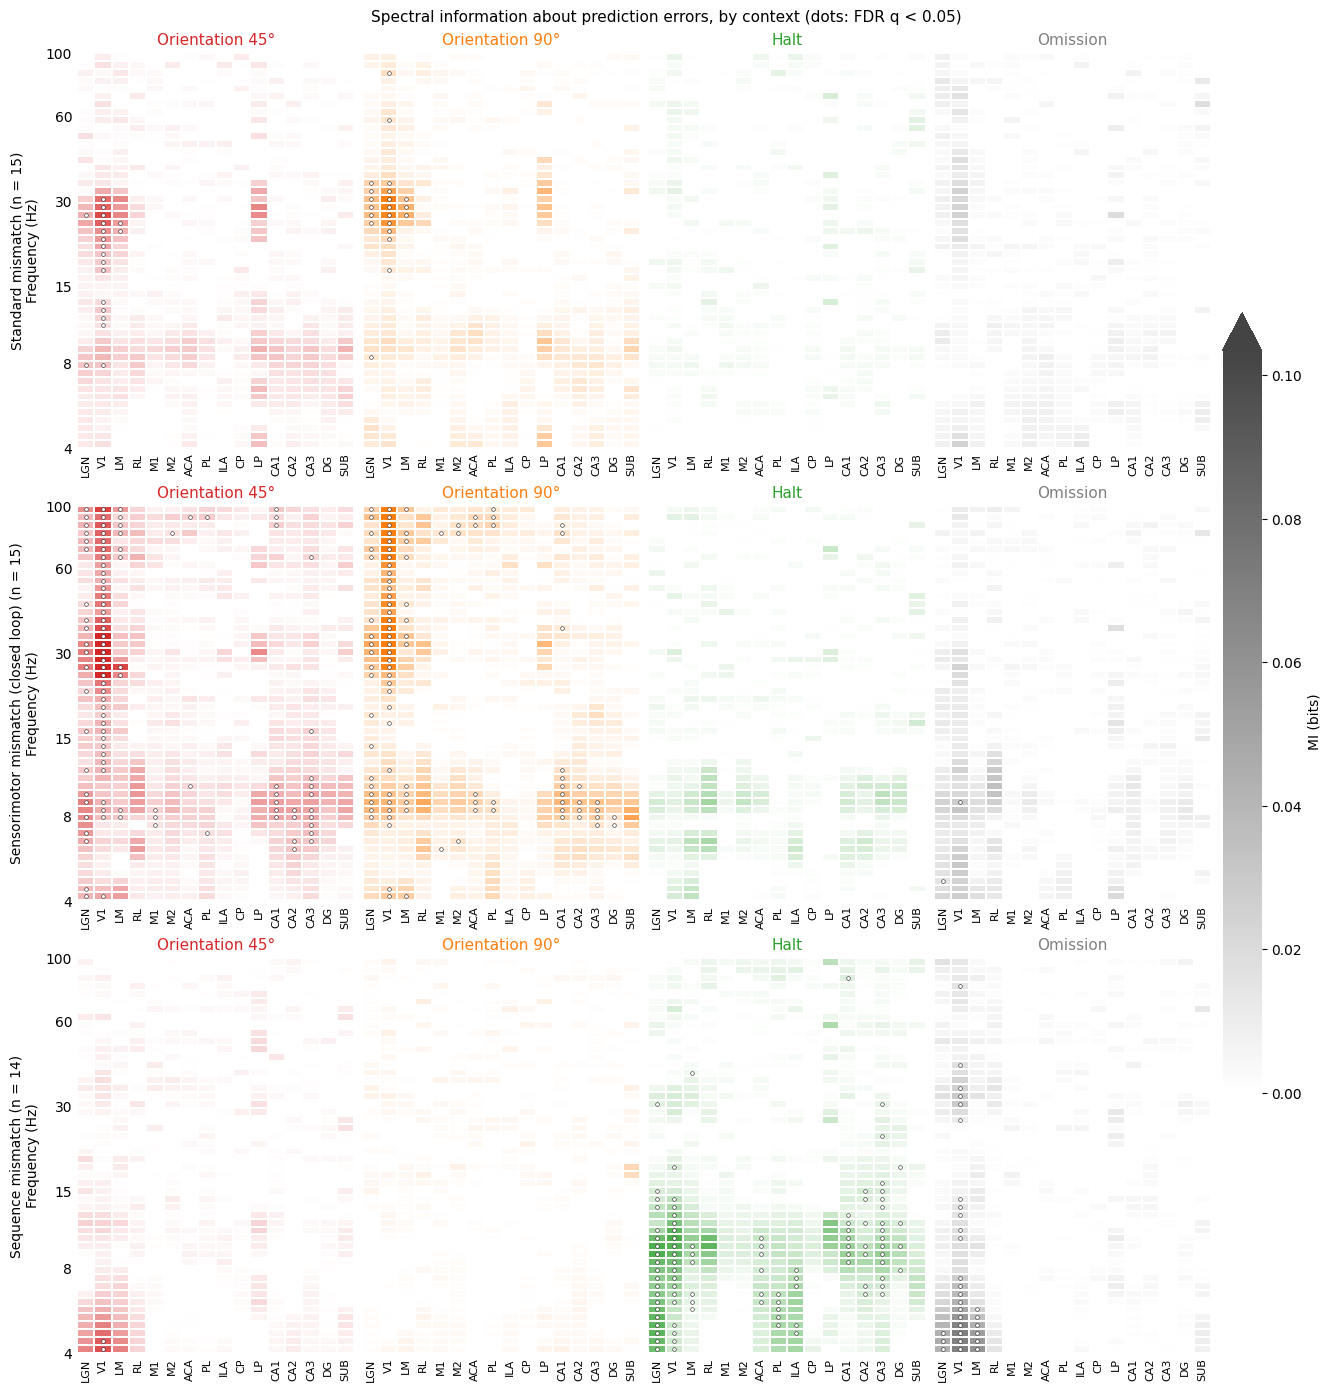

Saved to /content/drive/MyDrive/OpenScope_PP/oddball_MI/figures


In [20]:
#@title Comparison figure (needs at least two contexts)
FEATURES = list(BASE_LABELS)
AGGS = {c: g for c, g in AGGS_ALL.items()
        if set(FEATURES) <= {base_of(o) for o in g["oddballs"]}}
if len(AGGS) < 2:
    print(f"Only {list(AGGS) or 'no'} feature-oddball context(s) with MI so far.")
else:
    areas = [a for a in AREA_ORDER if any(a in g["show_areas"] for g in AGGS.values())]
    a_idx = [AREA_ORDER.index(a) for a in areas]
    vmax = max(np.nanpercentile(g["mi_mean"][:, a_idx, :], 99.5) for g in AGGS.values())

    fig, axes = plt.subplots(len(AGGS), 4, figsize=(3.0 * 4 + 1.2, 4.6 * len(AGGS)),
                             sharey=True, constrained_layout=True, squeeze=False)
    for row, (ctx, g) in zip(axes, AGGS.items()):
        odds = [next(o for o in g["oddballs"] if base_of(o) == b) for b in FEATURES]
        _, _, mesh = mi_heatmaps(g, axes=row, show_areas=areas, vmax=vmax, oddballs=odds,
                                 row_label=f"{g['label']} (n = {len(g['subjects'])})")
    cb = fig.colorbar(mesh, ax=axes, shrink=0.6, pad=0.01, extend="max")
    cb.set_label("MI (bits)")
    cb.outline.set_visible(False)
    fig.suptitle(f"Spectral information about prediction errors, by context "
                 f"(dots: FDR q < {ALPHA})", fontsize=11)
    out = context_dirs("standard")["figures"]
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(out, f"oddball_mi_by_context_{MI_TAG}.{ext}"),
                    dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved to {out}")

## 7 · Interactive main figure

Pick a **paradigm**, an **area** and an **oddball**. The paradigm changes everything (heatmap,
spectrum, example); the area changes the spectrum and the example and is kept when you
switch paradigm; the oddball changes only the example. All panels are the PNGs from
section 6, so this cell only reads files. **Save this view** writes the current
combination as one PNG next to the panels.

In [21]:
#@title Interactive figure: paradigm → area → oddball
import io as _io
import ipywidgets as W
from IPython.display import display
from PIL import Image as PILImage

with open(MANIFEST_FILE) as f:
    MAN = json.load(f)


def _png_bytes(fig):
    buf = _io.BytesIO()
    fig.savefig(buf, format="png", dpi=100, bbox_inches="tight")
    plt.close(fig)
    return buf.getvalue()


def _placeholder(text):
    fig, ax = plt.subplots(figsize=(4, 2))
    ax.text(0.5, 0.5, text, ha="center", va="center", color="#777777")
    ax.axis("off")
    return _png_bytes(fig)


def _read(rel_path, text):
    p = os.path.join(RESULTS_DIR, rel_path) if rel_path else None
    if p and os.path.exists(p):
        with open(p, "rb") as f:
            return f.read()
    return _placeholder(text)


dd_ctx = W.Dropdown(options=[(m["label"], c) for c, m in MAN.items()], description="Paradigm",
                    layout=W.Layout(width="340px"))
dd_area = W.Dropdown(description="Area", layout=W.Layout(width="200px"))
dd_odd = W.Dropdown(description="Oddball", layout=W.Layout(width="280px"))
btn = W.Button(description="Save this view", icon="download")
msg = W.HTML()
img_ex = W.Image(format="png", layout=W.Layout(width="640px"))
img_psd = W.Image(format="png", layout=W.Layout(width="360px"))
img_heat = W.Image(format="png", layout=W.Layout(width="1000px"))
_busy = {"on": False}


def _paths():
    m = MAN[dd_ctx.value]
    return (m["example"].get(f"{dd_area.value}|{dd_odd.value}"), m["psd"].get(dd_area.value),
            m["heatmap"])


def _show(*_):
    if _busy["on"]:
        return
    ex, psd, heat = _paths()
    img_ex.value = _read(ex, "No single-oddball example\nfor this area and oddball")
    img_psd.value = _read(psd, "No spectrum for this area")
    img_heat.value = _read(heat, "No heatmap")


def _on_ctx(*_):
    # New paradigm: keep the area if it exists there, and the same oddball type if it does.
    m = MAN[dd_ctx.value]
    area, odd = dd_area.value, dd_odd.value
    _busy["on"] = True
    dd_area.options = m["areas"]
    dd_area.value = area if area in m["areas"] else ("V1" if "V1" in m["areas"] else m["areas"][0])
    dd_odd.options = [(m["labels"][o], o) for o in m["oddballs"]]
    same = [o for o in m["oddballs"] if odd and base_of(o) == base_of(odd)]
    dd_odd.value = same[0] if same else m["oddballs"][0]
    _busy["on"] = False
    _show()


def _save(*_):
    ex, psd, heat = [os.path.join(RESULTS_DIR, p) if p else None for p in _paths()]
    if not all(p and os.path.exists(p) for p in (ex, psd, heat)):
        msg.value = "<i>Missing a panel for this view.</i>"
        return
    a, b, c = (PILImage.open(p).convert("RGB") for p in (ex, psd, heat))
    h = max(a.height, b.height)
    a = a.resize((int(a.width * h / a.height), h))
    b = b.resize((int(b.width * h / b.height), h))
    top_w = a.width + b.width
    c = c.resize((top_w, int(c.height * top_w / c.width)))
    canvas = PILImage.new("RGB", (top_w, h + c.height), "white")
    canvas.paste(a, (0, 0))
    canvas.paste(b, (a.width, 0))
    canvas.paste(c, (0, h))
    out = os.path.join(RESULTS_DIR, "figures",
                       f"main_figure_{dd_ctx.value}_{slug(dd_area.value)}_{slug(dd_odd.value)}.png")
    canvas.save(out)
    msg.value = f"Saved <code>{os.path.relpath(out, RESULTS_DIR)}</code>"


dd_ctx.observe(_on_ctx, "value")
dd_area.observe(_show, "value")
dd_odd.observe(_show, "value")
btn.on_click(_save)
_on_ctx()
display(W.VBox([W.HBox([dd_ctx, dd_area, dd_odd, btn]), msg,
                W.HBox([img_ex, img_psd]), img_heat]))

## 8 · Standalone HTML viewer

Writes `viewer.html` next to the results: the same three selectors as the interactive
figure above, as a plain web page. It embeds only the index of panels and loads the PNGs by
relative path, so it works by opening it locally after downloading the results folder, or
on GitHub Pages if the `figures/panels/` folders are committed next to it.

In [22]:
#@title Write viewer.html (the interactive figure as a standalone web page)
with open(MANIFEST_FILE) as f:
    _man = json.load(f)
for _m in _man.values():                                   # URLs always use forward slashes
    _m["heatmap"] = _m["heatmap"].replace(os.sep, "/") if _m["heatmap"] else None
    _m["psd"] = {k: v.replace(os.sep, "/") for k, v in _m["psd"].items()}
    _m["example"] = {k: v.replace(os.sep, "/") for k, v in _m["example"].items()}

VIEWER_HTML = '''<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Oddball spectral MI</title>
<style>
  :root { --ink: #1f2328; --muted: #6b7280; --line: #d9dde3; --bg: #ffffff; --panel: #ffffff; }
  @media (prefers-color-scheme: dark) {
    :root { --ink: #e6e8eb; --muted: #9aa3ad; --line: #3a3f45; --bg: #16181b; --panel: #ffffff; }
  }
  body { margin: 0; padding: 20px 16px 40px; background: var(--bg); color: var(--ink);
         font: 14px/1.4 system-ui, -apple-system, "Segoe UI", sans-serif; }
  main { max-width: 1120px; margin: 0 auto; }
  h1 { font-size: 18px; font-weight: 600; margin: 0 0 4px; }
  p.sub { margin: 0 0 16px; color: var(--muted); }
  .controls { display: flex; flex-wrap: wrap; gap: 12px 20px; margin-bottom: 16px; }
  label { display: flex; flex-direction: column; gap: 4px; font-size: 12px; color: var(--muted); }
  select { font: inherit; color: var(--ink); background: var(--bg); padding: 6px 8px;
           border: 1px solid var(--line); border-radius: 6px; min-width: 180px; }
  .top { display: grid; grid-template-columns: 64fr 36fr; gap: 12px; align-items: start; }
  figure { margin: 0; background: var(--panel); border: 1px solid var(--line);
           border-radius: 8px; padding: 6px; min-height: 60px; }
  figure img { display: block; width: 100%; height: auto; }
  figure .note { color: #777; padding: 24px; text-align: center; font-size: 13px; }
  figure .note:empty { display: none; }
  .bottom { margin-top: 12px; }
  @media (max-width: 760px) { .top { grid-template-columns: 1fr; } select { min-width: 0; } }
</style>
</head>
<body>
<main>
  <h1>Spectral information about prediction errors</h1>
  <p class="sub">OpenScope Community Predictive Processing · DANDI 001637 · LFP mutual information, standard vs oddball</p>
  <div class="controls">
    <label>Paradigm <select id="ctx"></select></label>
    <label>Area <select id="area"></select></label>
    <label>Oddball <select id="odd"></select></label>
  </div>
  <div class="top">
    <figure><img id="ex" alt="Example LFP trace and spectrogram"><div class="note" id="ex-note"></div></figure>
    <figure><img id="psd" alt="Power spectrum per condition"><div class="note" id="psd-note"></div></figure>
  </div>
  <figure class="bottom"><img id="heat" alt="MI heatmaps per oddball type"><div class="note" id="heat-note"></div></figure>
</main>
<script>
const MAN = __MANIFEST__;
const $ = (id) => document.getElementById(id);
const ctxSel = $("ctx"), areaSel = $("area"), oddSel = $("odd");
const base = (o) => (o || "").replace(/^motor_/, "");

function fill(sel, items) {
  sel.innerHTML = "";
  for (const [value, text] of items) {
    const o = document.createElement("option");
    o.value = value; o.textContent = text; sel.appendChild(o);
  }
}

function setImg(id, path, missing) {
  const img = $(id), note = $(id + "-note");
  if (path) { img.src = path; img.style.display = ""; note.textContent = ""; }
  else { img.removeAttribute("src"); img.style.display = "none"; note.textContent = missing; }
}

function show() {
  const m = MAN[ctxSel.value];
  setImg("ex", m.example[areaSel.value + "|" + oddSel.value],
         "No single-oddball example for this area and oddball");
  setImg("psd", m.psd[areaSel.value], "No spectrum for this area");
  setImg("heat", m.heatmap, "No heatmap");
  history.replaceState(null, "", "#" + [ctxSel.value, areaSel.value, oddSel.value].join("/"));
}

// New paradigm: keep the area if it exists there, and the same oddball type if it does.
function onCtx(area, odd) {
  const m = MAN[ctxSel.value];
  fill(areaSel, m.areas.map((a) => [a, a]));
  areaSel.value = m.areas.includes(area) ? area : (m.areas.includes("V1") ? "V1" : m.areas[0]);
  fill(oddSel, m.oddballs.map((o) => [o, m.labels[o]]));
  const same = m.oddballs.find((o) => odd && (o === odd || base(o) === base(odd)));
  oddSel.value = same || m.oddballs[0];
  show();
}

fill(ctxSel, Object.entries(MAN).map(([c, m]) => [c, m.label]));
const [hCtx, hArea, hOdd] = decodeURIComponent(location.hash.slice(1)).split("/");
if (hCtx && MAN[hCtx]) ctxSel.value = hCtx;
onCtx(hArea || "V1", hOdd);
ctxSel.addEventListener("change", () => onCtx(areaSel.value, oddSel.value));
areaSel.addEventListener("change", show);
oddSel.addEventListener("change", show);
</script>
</body>
</html>
'''

VIEWER_FILE = os.path.join(RESULTS_DIR, "viewer.html")
with open(VIEWER_FILE, "w", encoding="utf-8") as f:
    f.write(VIEWER_HTML.replace("__MANIFEST__", json.dumps(_man)))
print(f"Wrote {VIEWER_FILE}")
print("Open it from the downloaded results folder (it needs the figures/panels folders "
      "next to it), or commit both to a repo and enable GitHub Pages.")

Wrote /content/drive/MyDrive/OpenScope_PP/oddball_MI/viewer.html
Open it from the downloaded results folder (it needs the figures/panels folders next to it), or commit both to a repo and enable GitHub Pages.
